# Uso de Machine Learning en la predicción y prevención de ciberataques.

## Preprocesamiento y limpieza de datos

### Carga de los archivos

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

path = '/content/drive/MyDrive/MachineLearningCVE'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

pd.set_option('display.max_columns', None)

# Aseguramos que se use la ruta de Google Drive correcta.
try:
    if not path.startswith('/content/drive'):
        path = '/content/drive/MyDrive/MachineLearningCVE'
except NameError:
    path = '/content/drive/MyDrive/MachineLearningCVE'

files = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
]

dfs = []
for file in files:
    routePath = os.path.join(path, file)
    df_temp = pd.read_csv(routePath, low_memory=False)
    dfs.append(df_temp)
    print(f"{file}: {df_temp.shape}")

df_IDS = pd.concat(dfs, ignore_index=True)
print(f"\nDataset combinado: {df_IDS.shape}")

Monday-WorkingHours.pcap_ISCX.csv: (529918, 79)
Tuesday-WorkingHours.pcap_ISCX.csv: (445909, 79)
Wednesday-workingHours.pcap_ISCX.csv: (692703, 79)
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: (170366, 79)
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: (288602, 79)
Friday-WorkingHours-Morning.pcap_ISCX.csv: (191033, 79)
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: (286467, 79)
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: (225745, 79)

Dataset combinado: (2830743, 79)


### Estandarización de los nombres de las columnas

In [ ]:
# Normalización de las columnas.
def cleaningColumnName(name):
  name = name.strip()
  name = name.lower()
  name = name.replace(" ", "_")
  name = name.replace(",", "")
  name = name.replace("/", "_")
  name = name.replace("(", "")
  name = name.replace(")", "")
  name = name.replace("-", "_")


  return name

df_IDS.columns = [cleaningColumnName(cols) for cols in df_IDS.columns]

print(df_IDS["label"].value_counts())

label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
# Reemplazar carácter no-ASCII por un guión simple
df_IDS["label"] = df_IDS["label"].str.strip()
df_IDS["label"] = df_IDS["label"].str.replace(
    r'[�]+', '-', regex=True
)

print(df_IDS["label"].value_counts())


label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
print(df_IDS.columns.tolist())
print(f"\nShape: {df_IDS.shape}")

['destination_port', 'flow_duration', 'total_fwd_packets', 'total_backward_packets', 'total_length_of_fwd_packets', 'total_length_of_bwd_packets', 'fwd_packet_length_max', 'fwd_packet_length_min', 'fwd_packet_length_mean', 'fwd_packet_length_std', 'bwd_packet_length_max', 'bwd_packet_length_min', 'bwd_packet_length_mean', 'bwd_packet_length_std', 'flow_bytes_s', 'flow_packets_s', 'flow_iat_mean', 'flow_iat_std', 'flow_iat_max', 'flow_iat_min', 'fwd_iat_total', 'fwd_iat_mean', 'fwd_iat_std', 'fwd_iat_max', 'fwd_iat_min', 'bwd_iat_total', 'bwd_iat_mean', 'bwd_iat_std', 'bwd_iat_max', 'bwd_iat_min', 'fwd_psh_flags', 'bwd_psh_flags', 'fwd_urg_flags', 'bwd_urg_flags', 'fwd_header_length', 'bwd_header_length', 'fwd_packets_s', 'bwd_packets_s', 'min_packet_length', 'max_packet_length', 'packet_length_mean', 'packet_length_std', 'packet_length_variance', 'fin_flag_count', 'syn_flag_count', 'rst_flag_count', 'psh_flag_count', 'ack_flag_count', 'urg_flag_count', 'cwe_flag_count', 'ece_flag_count

### Revisión de valores infinitos y nulos

El dataset CIC-IDS2017 es conocido por contener valores infinitos en ciertas columnas, derivados de errores en el proceso de extracción de características. Esta es una de las etapas más importantes de la limpieza, ya que estos valores pueden distorsionar el entrenamiento del modelo si no se tratan correctamente.

In [ ]:
# Total de columnas del dataset
numCols = df_IDS.select_dtypes(include=[np.number]).columns

# Detección de columnas con valores infinitos
for cols in numCols:
  infinitos = np.isinf(df_IDS[cols]).sum()
  if infinitos > 0:
    print(f"La columna {cols} contiene {infinitos} valores infinitos")

La columna flow_bytes_s contiene 1509 valores infinitos
La columna flow_packets_s contiene 2867 valores infinitos


In [ ]:
# Distribución de valores infinitos por clase
infRows = df_IDS[np.isinf(df_IDS['flow_bytes_s']) | np.isinf(df_IDS['flow_packets_s'])]

countInfperClass = infRows['label'].value_counts()
print(f'Cantidad de filas con valores infinitos por clase:\n{countInfperClass}')

# Porcentaje de infinitos respecto al total de cada clase
percRelative = (countInfperClass / df_IDS['label'].value_counts() * 100).dropna().round(4)
print(f'\nPorcentaje de cada clase que presenta infinitos:\n{percRelative.sort_values(ascending=False)}')

Cantidad de filas con valores infinitos por clase:
label
BENIGN         1777
DoS Hulk        949
PortScan        126
Bot              10
FTP-Patator       3
DDoS              2
Name: count, dtype: int64

Porcentaje de cada clase que presenta infinitos:
label
Bot            0.5086
DoS Hulk       0.4107
PortScan       0.0793
BENIGN         0.0782
FTP-Patator    0.0378
DDoS           0.0016
Name: count, dtype: float64


In [ ]:
# Comprobación: los infinitos deben corresponder a flow_duration = 0
print(infRows['flow_duration'].describe())

# Conteo de filas infinitas donde flow_duration es exactamente 0
durationZero = (infRows['flow_duration'] == 0).sum()
totalInf = len(infRows)

print(f'\n{durationZero} de {totalInf} filas con infinitos tienen flow_duration = 0')
print(f'\nEsto representa el {durationZero/totalInf*100:.2f}% de los casos')

count    2867.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: flow_duration, dtype: float64

2867 de 2867 filas con infinitos tienen flow_duration = 0

Esto representa el 100.00% de los casos


#### Análisis del origen de los valores infinitos

Antes de aplicar cualquier tratamiento, es importante entender **por qué ocurren** estos valores y **en qué clases se concentran**, con el fin de descartar que su corrección introduzca un sesgo en el dataset.

**Hipótesis: origen matemático del problema**

Las columnas `flow_bytes_s` y `flow_packets_s` representan tasas (bytes por segundo y paquetes por segundo, respectivamente). Se calculan dividiendo el total de bytes o paquetes entre la duración del flujo (`flow_duration`). Cuando un flujo tiene duración igual a cero (es decir, se completó tan rápido que la herramienta no registró el tiempo transcurrido) la división produce un valor infinito.

**Evidencia**

El análisis confirma que el 100% de las filas con valores infinitos presentan `flow_duration = 0`. No existe ninguna causa externa identificada, el fenómeno es completamente matemático.

#### Distribución por clase

Al analizar en qué clases aparecen estos valores, se obtuvieron los siguientes resultados:

**Cantidad de filas con valores infinitos:**
- BENIGN: 1,777
- DoS Hulk: 949
- PortScan: 126
- Bot: 10
- FTP-Patator: 3
- DDoS: 2

**Porcentaje respecto al total de cada clase:**
- Bot: 0.5086 %
- DoS Hulk: 0.4107 %
- PortScan: 0.0793 %
- BENIGN: 0.0782 %
- FTP-Patator: 0.0378 %
- DDoS: 0.0016 %

**Conclusión:** Aunque Bot y DoS Hulk presentan una proporción relativamente mayor, en ningún caso supera el 1 % del total de la clase. La magnitud es demasiado pequeña como para generar un sesgo relevante al aplicar el tratamiento.

#### Reemplazo de valores infinitos

Con el origen de los infinitos confirmado, se procede a tratarlos. En lugar de limpiar cada columna individualmente, se aplica un único procedimiento sobre todo el DataFrame, lo que también contempla cualquier otro infinito que pudiera existir en columnas no detectadas previamente.

La decisión de reemplazar los infinitos por *NaN* y, posteriormente, imputarlos con *0*   mediante `fillna(0)` es coherente: si no transcurrió tiempo en el flujo, la tasa de bytes o paquetes por segundo debe interpretarse como cero, no como un dato faltante sin explicación. De esta forma se preserva el significado original de la variable sin distorsionar el dataset.

In [ ]:
df_IDS.replace([np.inf, -np.inf], np.nan, inplace=True)

Una vez que los valores infinitos han sido convertidos a nulos, se verifica el conteo total de valores faltantes en el dataset.

In [ ]:
for cols in numCols:
  nan = np.isnan(df_IDS[cols]).sum()
  if nan > 0:
    print(f"La columna {cols} contiene {nan} valores nulos")

La columna flow_bytes_s contiene 2867 valores nulos
La columna flow_packets_s contiene 2867 valores nulos


Con el conteo de nulos disponible, se obtiene el resumen descriptivo del dataset en su estado actual, previo al relleno de los valores faltantes.

In [ ]:
# Resumen estadístico del dataset previo al relleno de nulos
ids_resume = df_IDS.describe()
ids_resume

,destination_port,flow_duration,total_fwd_packets,total_backward_packets,total_length_of_fwd_packets,total_length_of_bwd_packets,fwd_packet_length_max,fwd_packet_length_min,fwd_packet_length_mean,fwd_packet_length_std,bwd_packet_length_max,bwd_packet_length_min,bwd_packet_length_mean,bwd_packet_length_std,flow_bytes_s,flow_packets_s,flow_iat_mean,flow_iat_std,flow_iat_max,flow_iat_min,fwd_iat_total,fwd_iat_mean,fwd_iat_std,fwd_iat_max,fwd_iat_min,bwd_iat_total,bwd_iat_mean,bwd_iat_std,bwd_iat_max,bwd_iat_min,fwd_psh_flags,bwd_psh_flags,fwd_urg_flags,bwd_urg_flags,fwd_header_length,bwd_header_length,fwd_packets_s,bwd_packets_s,min_packet_length,max_packet_length,packet_length_mean,packet_length_std,packet_length_variance,fin_flag_count,syn_flag_count,rst_flag_count,psh_flag_count,ack_flag_count,urg_flag_count,cwe_flag_count,ece_flag_count,down_up_ratio,average_packet_size,avg_fwd_segment_size,avg_bwd_segment_size,fwd_header_length.1,fwd_avg_bytes_bulk,fwd_avg_packets_bulk,fwd_avg_bulk_rate,bwd_avg_bytes_bulk,bwd_avg_packets_bulk,bwd_avg_bulk_rate,subflow_fwd_packets,subflow_fwd_bytes,subflow_bwd_packets,subflow_bwd_bytes,init_win_bytes_forward,init_win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,active_mean,active_std,active_max,active_min,idle_mean,idle_std,idle_max,idle_min
count,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.827876e+06,2.827876e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2830743.0,2.830743e+06,2830743.0,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2830743.0,2830743.0,2830743.0,2830743.0,2830743.0,2830743.0,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06,2.830743e+06
mean,8.071483e+03,1.478566e+07,9.361160e+00,1.039377e+01,5.493024e+02,1.616264e+04,2.075999e+02,1.871366e+01,5.820194e+01,6.891013e+01,8.708495e+02,4.104958e+01,3.059493e+02,3.353257e+02,1.491719e+06,7.085423e+04,1.298449e+06,2.919271e+06,9.182475e+06,1.623796e+05,1.448296e+07,2.610193e+06,3.266957e+06,9.042939e+06,1.021893e+06,9.893830e+06,1.805784e+06,1.485973e+06,4.684692e+06,9.672614e+05,4.644646e-02,0.0,1.112782e-04,0.0,-2.599739e+04,-2.273275e+03,6.386535e+04,6.995192e+03,1.643450e+01,9.504024e+02,1.719444e+02,2.949756e+02,4.861548e+05,3.537976e-02,4.644646e-02,2.423392e-04,2.980705e-01,3.158443e-01,9.482316e-02,1.112782e-04,2.433990e-04,6.835004e-01,1.919837e+02,5.820194e+01,3.059493e+02,-2.599739e+04,0.0,0.0,0.0,0.0,0.0,0.0,9.361160e+00,5.492919e+02,1.039377e+01,1.616230e+04,6.989837e+03,1.989433e+03,5.418218e+00,-2.741688e+03,8.155132e+04,4.113412e+04,1.531825e+05,5.829582e+04,8.316037e+06,5.038439e+05,8.695752e+06,7.920031e+06
std,1.828363e+04,3.365374e+07,7.496728e+02,9.973883e+02,9.993589e+03,2.263088e+06,7.171848e+02,6.033935e+01,1.860912e+02,2.811871e+02,1.946367e+03,6.886260e+01,6.052568e+02,8.396932e+02,2.594016e+07,2.544154e+05,4.507944e+06,8.045870e+06,2.445954e+07,2.950282e+06,3.357581e+07,9.525722e+06,9.639055e+06,2.452916e+07,8.591436e+06,2.873661e+07,8.887197e+06,6.278469e+06,1.716095e+07,8.308983e+06,2.104500e-01,0.0,1.054826e-02,0.0,2.105286e+07,1.452209e+06,2.475371e+05,3.815170e+04,2.523772e+01,2.028229e+03,3.054915e+02,6.318001e+02,1.647490e+06,1.847378e-01,2.104500e-01,1.556536e-02,4.574107e-01,4.648513e-01,2.929706e-01,1.054826e-02,1.559935e-02,6.804920e-01,3.318603e+02,1.860912e+02,6.052568e+02,2.105286e+07,0.0,0.0,0.0,0.0,0.0,0.0,7.496728e+

Una vez revisada la distribución del dataset, se reemplazan todos los valores nulos con cero mediante un único `fillna(0)`, en consistencia con la decisión tomada en el paso anterior.

In [ ]:
# Reemplazo de valores nulos por 0 (debido a que flow_duration = 0)
df_IDS.fillna(0, inplace=True)

Se verifica que el reemplazo haya sido aplicado correctamente mostrando las primeras cinco filas del dataset.

In [ ]:
# Verificación del resultado: primeras filas del dataset limpio
df_IDS.head()

,destination_port,flow_duration,total_fwd_packets,total_backward_packets,total_length_of_fwd_packets,total_length_of_bwd_packets,fwd_packet_length_max,fwd_packet_length_min,fwd_packet_length_mean,fwd_packet_length_std,bwd_packet_length_max,bwd_packet_length_min,bwd_packet_length_mean,bwd_packet_length_std,flow_bytes_s,flow_packets_s,flow_iat_mean,flow_iat_std,flow_iat_max,flow_iat_min,fwd_iat_total,fwd_iat_mean,fwd_iat_std,fwd_iat_max,fwd_iat_min,bwd_iat_total,bwd_iat_mean,bwd_iat_std,bwd_iat_max,bwd_iat_min,fwd_psh_flags,bwd_psh_flags,fwd_urg_flags,bwd_urg_flags,fwd_header_length,bwd_header_length,fwd_packets_s,bwd_packets_s,min_packet_length,max_packet_length,packet_length_mean,packet_length_std,packet_length_variance,fin_flag_count,syn_flag_count,rst_flag_count,psh_flag_count,ack_flag_count,urg_flag_count,cwe_flag_count,ece_flag_count,down_up_ratio,average_packet_size,avg_fwd_segment_size,avg_bwd_segment_size,fwd_header_length.1,fwd_avg_bytes_bulk,fwd_avg_packets_bulk,fwd_avg_bulk_rate,bwd_avg_bytes_bulk,bwd_avg_packets_bulk,bwd_avg_bulk_rate,subflow_fwd_packets,subflow_fwd_bytes,subflow_bwd_packets,subflow_bwd_bytes,init_win_bytes_forward,init_win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,active_mean,active_std,active_max,active_min,idle_mean,idle_std,idle_max,idle_min,label
0,49188,4,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,3000000.0,5.000000e+05,4.0,0.0,4,4,4,4.0,0.0,4,4,0,0.0,0.0,0,0,0,0,0,0,40,0,5.000000e+05,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,12000000.0,2.000000e+06,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,40,0,2.000000e+06,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,12000000.0,2.000000e+06,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,40,0,2.000000e+06,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,12000000.0,2.000000e+06,1.0,0.0,1,1,1,1.0,0.0,1,1,0,0.0,0.0,0,0,0,0,0,0,40,0,2.000000e+06,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4000000.0,6.666667e+05,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,6.666667e+05,0.0,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


## EDA — Análisis Exploratorio de Datos

Con los datos cargados, las columnas estandarizadas y los valores problemáticos tratados, se puede proceder con el análisis exploratorio. Aunque algunos de los indicadores ya se revisaron durante la limpieza, se documentan aquí de forma consolidada para mantener la trazabilidad del proceso y facilitar la lectura del notebook como un todo coherente.

### Resumen de la fase de limpieza

Los valores nulos e infinitos fueron tratados durante el preprocesamiento (sección *Revisión de valores infinitos y nulos*). Se documentan a continuación con magnitudes relativas respecto al total del dataset, con el fin de dejar registro claro del rigor metodológico aplicado antes del análisis exploratorio.

In [ ]:
# Resumen cuantitativo de los valores tratados durante el preprocesamiento
totRows = 2830743

clSummary = pd.DataFrame({
    'Problemas detectados': [
        'Números infinitos en flow_bytes_s',
        'Números infinitos en flow_packets_s',
        'Nulos en flow_bytes_s (despues de la conversion de infinitos a NaN)',
        'Nulos en flow_packets_s (despues de la conversion de infinitos a NaN)',
    ],
    'Cantidades': [1509, 2867, 2867, 2867],
    '% del total': [
        round(1509/totRows*100, 4),
        round(2867/totRows*100, 4),
        round(2867/totRows*100, 4),
        round(2867/totRows*100, 4),
    ]
})

clSummary

,Problemas detectados,Cantidades,% del total
0,Números infinitos en flow_bytes_s,1509,0.0533
1,Números infinitos en flow_packets_s,2867,0.1013
2,Nulos en flow_bytes_s (despues de la conversio...,2867,0.1013
3,Nulos en flow_packets_s (despues de la convers...,2867,0.1013


### Estructura y dimensión del dataset

In [ ]:
import pandas as pd

# Dimensiones del dataset
print(f'El dataset contiene un total de {df_IDS.shape} filas y columnas (respectivamente)\n')

# Configuramos pandas para que no trunque las filas al imprimir series o dataframes
pd.set_option('display.max_rows', None)

# Tipos de dato por columna (dtypes)
# Permite distinguir columnas numéricas de categóricas
print("Los tipos de datos de las columnas son:\n", df_IDS.dtypes)

# Uso de memoria del dataset
print(f'\nEl dataset ocupa una memoria de:\n{df_IDS.memory_usage()}')

# Restauramos la opción por defecto para no afectar celdas futuras
pd.reset_option('display.max_rows')

El dataset contiene un total de (2830743, 79) filas y columnas (respectivamente)

Los tipos de datos de las columnas son:
 destination_port                 int64
flow_duration                    int64
total_fwd_packets                int64
total_backward_packets           int64
total_length_of_fwd_packets      int64
total_length_of_bwd_packets      int64
fwd_packet_length_max            int64
fwd_packet_length_min            int64
fwd_packet_length_mean         float64
fwd_packet_length_std          float64
bwd_packet_length_max            int64
bwd_packet_length_min            int64
bwd_packet_length_mean         float64
bwd_packet_length_std          float64
flow_bytes_s                   float64
flow_packets_s                 float64
flow_iat_mean                  float64
flow_iat_std                   float64
flow_iat_max                     int64
flow_iat_min                     int64
fwd_iat_total                    int64
fwd_iat_mean                   float64
fwd_iat_std        

El paper original de CIC-IDS-2017 advierte que es posible encontrar filas duplicadas entre archivos, lo que podría inflar artificialmente ciertas clases. Se realiza un conteo para determinar si este es el caso en el dataset cargado.

In [ ]:
# Conteo de filas completamente duplicadas
duplicatedRows = df_IDS.duplicated().sum()
print(f"Total de filas duplicadas: {duplicatedRows}")

Total de filas duplicadas: 308381


#### Limpieza de filas duplicadas

**Hallazgo:** El total de filas duplicadas representa aproximadamente el 10.89 % del dataset, una proporción llamativa que merece atención.

**Análisis previo a la eliminación:** Antes de proceder, es necesario evaluar cómo afecta la eliminación a las clases minoritarias. Debido a que si una clase ya cuenta con pocas muestras y una parte significativa de ellas son duplicados, eliminarlas reduciría aún más su representación en el dataset.

In [ ]:
# Distribución de duplicados por clase

# DataFrame temporal con las filas duplicadas
duplicated = df_IDS[df_IDS.duplicated()]

# Conteo de filas totales por clase
countDuplicatedbyClases = duplicated['label'].value_counts()

# Total de filas por clase (antes de eliminar duplicados)
print(f'Cantidad de filas por cada clase:\n{df_IDS['label'].value_counts()}')



Cantidad de filas por cada clase:
label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [ ]:
# Duplicados por clase
print(f'Cantidad de filas duplicadas por clase:\n{countDuplicatedbyClases}')

Cantidad de filas duplicadas por clase:
label
BENIGN                      176613
PortScan                     68111
DoS Hulk                     58224
SSH-Patator                   2678
FTP-Patator                   2005
DoS slowloris                  411
DoS Slowhttptest               271
Web Attack - Brute Force        37
Bot                             13
DDoS                            11
DoS GoldenEye                    7
Name: count, dtype: int64


**Hallazgo:** El conteo revela que, si bien la mayoría de las clases no se ven gravemente afectadas, PortScan y SSH-Patator perderían casi la mitad de sus muestras.

**Interpretación:** Tras investigar el origen del problema, se identificó que la herramienta CICFlowMeter (la cual fue la encargada de extraer las características del tráfico de red) divide incorrectamente ciertas conexiones TCP, generando registros duplicados. Se trata, por tanto, de un defecto conocido del dataset, no de una característica del tráfico real. Múltiples publicaciones académicas documentan este comportamiento y respaldan su eliminación (Lanvin et al., 2022). Incluso existen versiones revisadas del dataset construidas específicamente para corregir este problema.

**Acción:** Se eliminan las filas duplicadas.


In [ ]:
# Eliminación de filas duplicadas
df_IDS.drop_duplicates(inplace=True)

# Verificación de la nueva dimensión del dataset
df_IDS.shape

(2522362, 79)

En total se perdieron 308,381 filas tras la eliminación de duplicados. La distribución de pérdidas por tipo de ataque fue la siguiente:

- Benigno: 176,613
- DoS Hulk: 58,224
- PortScan: 68,111
- DDoS: 11
- DoS GoldenEye: 7
- FTP-Patator: 2,005
- SSH-Patator: 2,678
- DoS Slowloris: 411
- DoS Slowhttptest: 271
- Bot: 13
- Web Attack Brute Force: 37
- Web Attack XSS: 0
- Infiltration: 0
- Web Attack SQL Injection: 0
- Heartbleed: 0

### Análisis de la variable objetivo (label/clase)

In [ ]:
# Conteo de clases únicas presentes en el dataset
# Número de clases únicas
print(f'El dataset contiene {df_IDS['label'].nunique()} clases')
print(f'Las clases son:\n{df_IDS['label'].unique()}')

El dataset contiene 15 clases
Las clases son:
['BENIGN' 'FTP-Patator' 'SSH-Patator' 'DoS slowloris' 'DoS Slowhttptest'
 'DoS Hulk' 'DoS GoldenEye' 'Heartbleed' 'Web Attack - Brute Force'
 'Web Attack - XSS' 'Web Attack - Sql Injection' 'Infiltration' 'Bot'
 'PortScan' 'DDoS']


El dataset completo contiene 15 clases, tal como se había observado previamente:

1. Tráfico benigno (BENIGN)
2. Escaneo de puertos (PortScan)
3. Ataques web de fuerza bruta (Web Attack Brute Force)
4. Ataques web XSS (Web Attack XSS)
5. Inyección SQL (Web Attack SQL Injection)
6. FTP-Patator
7. SSH-Patator
8. DDoS
9. Bot
10. Infiltración (Infiltration)
11. DoS Slowloris
12. DoS Slowhttptest
13. DoS Hulk
14. DoS GoldenEye
15. Heartbleed

In [ ]:
# Conteo absoluto por clase
countByClass = df_IDS['label'].value_counts()

# Porcentaje de cada clase respecto al total
porcentajeByClass = df_IDS['label'].value_counts(normalize=True) * 100

# DataFrame consolidado con conteo y porcentaje por clase
df_count = pd.DataFrame(
    {
        'Conteo': countByClass,
        'porcentaje %': porcentajeByClass.round(2)
    })

df_count

,Conteo,porcentaje %
label,,
BENIGN,2096484,83.12
DoS Hulk,172849,6.85
DDoS,128016,5.08
PortScan,90819,3.60
DoS GoldenEye,10286,0.41
FTP-Patator,5933,0.24
DoS slowloris,5385,0.21
DoS Slowhttptest,5228,0.21
SSH-Patator,3219,0.13


#### Imbalance Ratio (IR)

El *Imbalance Ratio* (IR), o relación de desequilibrio, es una métrica numérica que cuantifica qué tan desbalanceadas están las clases en un dataset. Se calcula como la razón entre la clase mayoritaria y la clase minoritaria.

In [ ]:
# Identificación de la clase mayoritaria y la minoritaria
claseMax = countByClass.idxmax()
claseMin = countByClass.idxmin()

# Cálculo del Imbalance Ratio (IR)
IR = countByClass.max() / countByClass.min()

# Resultados
print(f'Clase Mayoritaria: {claseMax}. Tiene {countByClass.max()} filas')
print(f'Clase Minoritaria: {claseMin}. Tiene {countByClass.min()} filas')
print(f'Relacion de desequilibrio de {IR:.2f}')


Clase Mayoritaria: BENIGN. Tiene 2096484 filas
Clase Minoritaria: Heartbleed. Tiene 11 filas
Relacion de desequilibrio de 190589.45


#### Granularidad

**Decisión de granularidad de la etiqueta:** Para continuar con el modelado, es necesario definir cómo se tratará la variable objetivo.

Las opciones disponibles eran:
- **Clasificación multiclase:** cada tipo de ataque es una clase independiente.
- **Clasificación binaria:** tráfico benigno (0) vs. tráfico de ataque (1).
- **Clasificación multiclase agrupada por familia:** los ataques se agrupan en categorías según su naturaleza.

Con base en lo observado durante el EDA (principalmente el desequilibrio extremo entre clases y la presencia de clases con muy pocas muestras (Heartbleed: 11,  Web Attack - Sql Injection: 21, Infiltration: 36)) se optó por una  **clasificación multiclase agrupada por familia de ataque**. Esta decisión permite mantener la capacidad de distinción de los tipos de ataque sin sacrificar la viabilidad estadística del entrenamiento, agrupando las clases minoritarias en categorías con suficiente representación.

### Colinealidad y utilidad de las columnas

#### Multicolinealidad: columnas duplicadas o redundantes

**Hipótesis:** En datasets de tráfico de red es común que distintas columnas capturen, en realidad, la misma información con nombres distintos. Esto se conoce como multicolinealidad: dos o más columnas que se mueven de forma prácticamente idéntica (si una sube, la otra también lo hace).

Si dos columnas tienen una correlación superior al 99 %, el modelo no gana nada conservando ambas, solo se incrementa la dimensionalidad del dataset sin añadir información nueva. Se identifican estos grupos para eliminar las columnas redundantes.

In [ ]:
# Matriz de correlación sobre columnas numéricas
matrizCorrelacion = df_IDS.drop(columns=['label']).corr()

# Extracción de pares con correlación superior al umbral definido
umbral = 0.90

paresCorr = []

# Solo la mitad superior evita duplicar pares (A,B) y (B,A)
for i in range(len(matrizCorrelacion.columns)):
  for j in range(i+1, len(matrizCorrelacion.columns)):
    val = matrizCorrelacion.iloc[i, j]
    if abs(val) >= umbral:
      col1 = matrizCorrelacion.columns[i]
      col2 = matrizCorrelacion.columns[j]
      paresCorr.append((col1, col2, round(val, 4)))

# Resultado como DataFrame para facilitar la lectura
df_pares = pd.DataFrame(paresCorr, columns=['Columna 1', 'Columna 2', 'Correlacion'])
df_pares = df_pares.sort_values('Correlacion', key=abs, ascending=False)

print(f'Se encontraron {len(df_pares)} pares con correlación >= {umbral}')
df_pares.to_csv("pares_correlacion.csv", index=False)
df_pares

Se encontraron 71 pares con correlación >= 0.9


,Columna 1,Columna 2,Correlacion
3,total_fwd_packets,subflow_fwd_packets,1.0000
50,fwd_urg_flags,cwe_flag_count,1.0000
26,bwd_packet_length_mean,avg_bwd_segment_size,1.0000
15,fwd_packet_length_mean,avg_fwd_segment_size,1.0000
13,total_length_of_bwd_packets,subflow_bwd_bytes,1.0000
...,...,...,...
67,active_mean,active_min,0.9057
43,fwd_iat_std,idle_mean,0.9032
22,bwd_packet_length_mean,max_packet_length,0.9031
55,max_packet_length,avg_bwd_segment_size,0.9031


#### Correlaciones

Con la tabla de correlaciones completa, se identifican los siguientes grupos:

- **Conteos totales vs. subflow:** Las columnas `subflow_*` son casi una copia exacta de las columnas `total_*`.
- **Medias vs. avg_segment_size:** Se trata de la misma métrica con dos nombres distintos.
- **Duplicado literal:** El paper de referencia (Lanvin et al., 2022) documenta que `Fwd Header Length` está duplicada en el dataset por un error del CICFlowMeter.
- **Tiempos entre paquetes e inactividad:** `flow_duration`, `fwd_iat_total` y columnas relacionadas miden variaciones del mismo concepto.
- **Longitud de paquetes:** Las columnas de máximo, desviación estándar y media de longitud de paquetes contienen información prácticamente idéntica.
- **Flags TCP (PSH y SYN):** Aunque son flags completamente distintos, la correlación observada es de 1.0. Antes de eliminar alguna de ellas, se requiere un análisis más profundo para descartar que sea una coincidencia del subconjunto analizado.
- **Tasas:** `flow_packets_s` y `fwd_packets_s` capturan prácticamente la misma información.

Sin embargo, debido a que el profesor nos recomendo ajustar el umbral a 0.90, logramos identificar
32 pares adicionales respecto al análisis previo.

Los nuevos grupos detectados son:

- **Desviaciones estándar de IAT:** Las columnas `flow_iat_std` y `fwd_iat_std`
  presentan correlaciones superiores a 0.90 con `flow_iat_max`, `fwd_iat_max` y
  las columnas del grupo idle (idle_max, idle_mean, idle_min), confirmando que la
  variabilidad del tiempo entre paquetes ya queda capturada por los extremos
  previamente conservados.

- **Backward IAT media vs. mínimo:** `bwd_iat_mean` y `bwd_iat_min` muestran una
  correlación de 0.9331, siendo la media la representación más interpretable e
  informativa del par.

- **IAT de flujo vs. IAT forward:** `flow_iat_mean` y `fwd_iat_mean` presentan
  una correlación de 0.9019. Al medir el flujo completo en ambas direcciones,
  `flow_iat_mean` es la más general y suficiente.

- **Varianza vs. desviación estándar de longitud de paquetes:** `packet_length_std`
  y `packet_length_variance` tienen una correlación de 0.9249. Matemáticamente,
  la varianza es el cuadrado de la desviación estándar, por lo que contienen
  exactamente la misma información en diferente escala.

- **Active media vs. mínimo:** `active_mean` y `active_min` correlacionan en 0.9057.
  A diferencia del grupo idle (en se donde se optó por conservar ambos extremos por su
  capacidad discriminativa), las columnas *active* mostraron menor relevancia visual
  en los boxplots por clase, por lo que la media es suficiente.

- **Cluster de longitud de paquetes:** Con el umbral de 0.90 se hace visible que
  `bwd_packet_length_max`, `bwd_packet_length_std`, `bwd_packet_length_mean`,
  `max_packet_length`, `packet_length_mean`, `average_packet_size` y
  `avg_bwd_segment_size` forman un cluster de alta correlación. Las decisiones
  tomadas en el análisis previo (conservar medias y máximos, eliminar desviaciones
  estándar y duplicados avg) se mantienen y quedan reforzadas por este hallazgo.

- **Flags cuasi-constantes correlacionadas:** Al consolidar el análisis de varianza dentro de este apartado, emergen dos pares adicionales que anteriormente habrían sido eliminados en una etapa previa. `fwd_urg_flags` y `cwe_flag_count` presentan una correlación de 1.0, mientras que `rst_flag_count` y `ece_flag_count` correlacionan en 0.9978. En ambos casos se trata de flags TCP con valores prácticamente constantes en todo el dataset.

  > **Nota:** Estos pares surgen directamente como consecuencia de haber
  > consolidado el análisis de columnas constantes y cuasi-constantes dentro del presente apartado de correlación, en lugar de tratarlos como una etapa separada.

#### Solución recomendable:

Para la mayoría de casos emplearemos únicamente la eliminación de la columna
menos entendible, la más difícil de interpretar.

Los únicos puntos que se debían analizar más a profundidad eran el cluster de
tiempos entre paquetes y las flags.

En cuanto al cluster de **tiempos entre paquetes** se consideró conservar
únicamente los extremos *idle_min*, *idle_max* en lugar de la media *idle_mean*,
debido a que se consideraba que la media no es tan vital, mientras que los extremos
capturaban la variabilidad real.

Debido a que nuestro objetivo es que el modelo distinga patrones de comportamiento
entre clases, los extremos son considerados en ocasiones como más informativos que
el promedio.

Sin embargo, en la tabla mostrada podemos notar que *idle_max* e *idle_min* también
están correlacionados entre sí. Esto significa que, si elegimos los extremos,
podemos resolver la redundancia con la media, pero no la redundancia entre las
mismas dos columnas.

Este es una problemática, debido a que nos enfrentábamos a la reducción de
dimensionalidad al máximo con la contradicción de tener que sacrificar algo de
información acerca de la variabilidad, o priorizar el conservar información sobre
el rango/variabilidad del comportamiento a costa de dejar un par correlacionado
sin resolver.

Al final, se optó por conservar tanto *idle_min* e *idle_max*, pese a tener una
correlación de 0.9613 entre sí, debido a que ambos extremos pueden capturar
patrones de comportamiento distintivos que se perderían en caso de que únicamente
se conservara la media *idle_mean*.

Para el cluster de **Flags** tenemos que confirmar que la correlación de 1.0 no
se trata de una casualidad extraña del subconjunto de datos, sino de un patrón
completo y consistente.

Entonces, realizamos el siguiente fragmento de código para analizar dos cosas:
cómo se distribuyen los valores de cada columna por separado, y si realmente
coinciden fila por fila.

---

Al ajustar el umbral a 0.90 por recomendación del asesor, se identificaron 32
pares adicionales. Para los grupos ya analizados, las decisiones tomadas se
mantienen y quedan reforzadas (el cluster de longitud de paquetes y el de tiempos
entre paquetes simplemente muestran más conexiones internas, pero no contradicen
ninguna elección previa).

Los grupos nuevos que requieren decisión son:

- **Desviaciones estándar de IAT:** `flow_iat_std` y `fwd_iat_std` correlacionan
  por encima de 0.90 con `flow_iat_max`, `fwd_iat_max` y las columnas idle,
  confirmando que la variabilidad del tiempo entre paquetes ya queda capturada
  por los extremos conservados. Se eliminan ambas columnas.

- **Backward IAT media vs. mínimo:** `bwd_iat_mean` y `bwd_iat_min` presentan
  una correlación de 0.9331. Se conserva `bwd_iat_mean` por ser más interpretable
  y se elimina `bwd_iat_min`.

- **IAT de flujo vs. IAT forward:** `flow_iat_mean` y `fwd_iat_mean` correlacionan
  en 0.9019. Se conserva `flow_iat_mean` por capturar el flujo completo en ambas
  direcciones, y se elimina `fwd_iat_mean`.

- **Varianza vs. desviación estándar de longitud de paquetes:**
  `packet_length_variance` y `packet_length_std` correlacionan en 0.9249.
  Matemáticamente son la misma información en distinta escala, debido a que la varianza es
  el cuadrado de la desviación estándar. Se elimina `packet_length_variance`.

- **Active media vs. mínimo:** `active_mean` y `active_min` correlacionan en
  0.9057. A diferencia del grupo idle, donde se conservaron ambos extremos por
  su capacidad discriminativa entre clases, las columnas active mostraron menor
  relevancia en los boxplots por clase. Se conserva `active_mean` y se elimina
  `active_min`.

- Se elimina `cwe_flag_count` sobre `fwd_urg_flags` por tener menor interpretabilidad técnica en el contexto de detección de intrusiones, y se elimina `ece_flag_count` sobre `rst_flag_count` por la misma razón — los resets de conexión (`rst`) son indicadores reconocidos de escaneos y comportamiento anómalo, mientras que `ece` carece de relevancia práctica en este contexto.

In [ ]:
# Distribución de valores en cada columna de flags
print("fwd_psh_flags:")
print(df_IDS['fwd_psh_flags'].value_counts(normalize=True))

print("\nsyn_flag_count:")
print(df_IDS['syn_flag_count'].value_counts(normalize=True))

# Coincidencias fila a fila entre las columnas de flags
# para confirmar si la correlación es real o un artefacto del subconjunto
coin = (df_IDS['fwd_psh_flags'] == df_IDS['syn_flag_count']).sum()
total = len(df_IDS)

print(f"\nCoinciden en {coin} de {total} filas ({coin/total*100:.2f}%)")

# Distribución de coincidencias por clase
# Filas donde ambos flags están activos
actRow = df_IDS[df_IDS['fwd_psh_flags'] == 1]
print('\n',actRow['label'].value_counts())

fwd_psh_flags:
fwd_psh_flags
0    0.951262
1    0.048738
Name: proportion, dtype: float64

syn_flag_count:
syn_flag_count
0    0.951262
1    0.048738
Name: proportion, dtype: float64

Coinciden en 2522362 de 2522362 filas (100.00%)

 label
BENIGN              118841
FTP-Patator           1944
DoS slowloris         1429
DoS Slowhttptest       687
Infiltration            20
SSH-Patator             14
Name: count, dtype: int64


Este resultado concluye con cualquier duda. Las filas de ambas columnas coinciden en un 100%, sin ninguna excepcion en 2,522,362 registros. No es un problema del subconjunto, sino que genuinamente son la misma informacion repetida en dos columnas distintas.

La decision final es la eliminacion de una de las dos. La columna que se conservará será syn_flag_count debido a que sigue la misma convencion de nombres que el resto de las columnas que vamos a conservar. Esto ayudara a la interpretacion final del dataset, asi como la interpretacion de feature importance que se realizara posteriormente.

In [ ]:
# Eliminación de columnas redundantes (correlación ≥ 0.90)
multiCols = [
    # Pares originales (umbral 0.95)
    # Subflow = copia exacta de total
    'subflow_fwd_packets', 'subflow_bwd_packets',
    'subflow_fwd_bytes', 'subflow_bwd_bytes',
    # Medias vs avg_segment_size (misma métrica, dos nombres)
    'avg_fwd_segment_size', 'avg_bwd_segment_size',
    # Duplicado literal documentado por Lanvin et al. (2022)
    'fwd_header_length.1',
    # Tiempos entre paquetes
    'fwd_iat_total', 'fwd_iat_max', 'idle_mean',
    # Longitud de paquetes
    'bwd_packet_length_std', 'fwd_packet_length_std', 'packet_length_std',
    # Flags (PSH = SYN al 100% confirmado)
    'fwd_psh_flags', 'cwe_flag_count', 'ece_flag_count',
    # Tasas
    'fwd_packets_s',
    # Tamaño promedio de paquete
    'average_packet_size',

    # --- Pares nuevos (umbral 0.90) ---
    # Desviaciones estándar de IAT redundantes con extremos conservados
    'flow_iat_std', 'fwd_iat_std',
    # Backward IAT mínimo redundante con media
    'bwd_iat_min',
    # IAT forward redundante con IAT de flujo completo
    'fwd_iat_mean',
    # Varianza = desviación estándar al cuadrado
    'packet_length_variance',
    # Active mínimo redundante con media
    'active_min',

]

df_IDS.drop(columns=multiCols, inplace=True)
print(f"Nueva forma del dataset: {df_IDS.shape}")

Nueva forma del dataset: (2522362, 55)


### Distribución estadística de las features numéricas

Pese a que ya tenemos el .describe() que nos ayuda generalmente en la fase de limpieza, tambien es necesario que se profundice en tres apartados especificos.

El primer apartado es la **asimetría**. Esta mide que tan "desbalanceada" esta la distribucion de una columna respecto a una curva normal (simetrica).

Los valores de skewness se identifican de la siguiente manera:
- Cercano a 0: distribucion simetrica.
- Positivo alto: una cola larga hacia la derecha (es decir, muchos valores bajos, pocos valores muy altos).
- Negativo alto: cola larga hacia la izquierda.

Esto es relevante debido a que en el trafico de red **se espera** que la mayoria de features tengan skewness alto. Esto no indicaria un error en si mismo, pero es completamente relevante y necesita de una documentacion apropiada.

Es importante entender que nuestro modelo elegido (Random Forest) no requiere normalidad, a diferencia de otros modelos, asi que no es necesario que el skew sea arreglado a la fuerza.

Aun asi, en caso de obtener un skew extremo, podemos basarnos en este para ayudarnos a identificar aquellas features candidatas a una transformacion logaritmica si es que en algun momento deseamos hacer una comparacion con otro modelo.  

In [ ]:
# Cálculo de la asimetría (skewness) de todas las columnas numéricas
skewness = df_IDS.drop(columns=['label']).skew().sort_values(ascending=False)

print("Skewness por columna: \n")
print(skewness)

Skewness por columna: 

total_length_of_fwd_packets     760.815157
act_data_pkt_fwd                268.646876
total_backward_packets          230.968239
total_fwd_packets               230.686315
total_length_of_bwd_packets     230.638229
fwd_urg_flags                   177.557209
rst_flag_count                   60.612847
flow_bytes_s                     45.686523
active_std                       38.244287
active_mean                      36.152458
flow_iat_min                     23.489076
active_max                       23.030023
bwd_packets_s                    21.713153
fwd_packet_length_min            19.338026
down_up_ratio                    12.570369
min_packet_length                10.550888
idle_std                          9.889364
fwd_packet_length_max             9.338494
fwd_iat_min                       9.211661
fwd_packet_length_mean            8.686560
flow_iat_mean                     8.500915
bwd_iat_mean                      7.778063
flow_packets_s                

In [ ]:
# Columnas con mayor asimetría en ambas direcciones
# Top 10: skewness positivo (cola hacia la derecha)
print('Mayor asimetria positiva: \n')
print(skewness.head(10))
# Top 10: skewness negativo (cola hacia la izquierda)
print('\n Mayor asimetria negativa: \n')
print(skewness.tail(10))

Mayor asimetria positiva: 

total_length_of_fwd_packets    760.815157
act_data_pkt_fwd               268.646876
total_backward_packets         230.968239
total_fwd_packets              230.686315
total_length_of_bwd_packets    230.638229
fwd_urg_flags                  177.557209
rst_flag_count                  60.612847
flow_bytes_s                    45.686523
active_std                      38.244287
active_mean                     36.152458
dtype: float64

 Mayor asimetria negativa: 

bwd_psh_flags              0.000000
bwd_urg_flags              0.000000
fwd_avg_packets_bulk       0.000000
fwd_avg_bytes_bulk         0.000000
bwd_avg_packets_bulk       0.000000
bwd_avg_bytes_bulk         0.000000
fwd_avg_bulk_rate          0.000000
min_seg_size_forward    -447.941881
bwd_header_length       -676.848513
fwd_header_length      -1250.816374
dtype: float64


#### Problematicas con la asimetria negativa.

Al hacer el calculo del coeficiene de asimetria, la mayoria de las columnas presentaron valores dentro de un rango esperable para datos de trafico de red (asimetria positiva moderada a alta).

Sin embargo, tres columnas presentaron valores de asimetria considerablemente mas extremos que el resto del conjunto de datos: *min_seg_size_forward* (-447.94), *bwd_header_length* (-676.85), *fwd_header_length* (-1250.82). Estos valores son ordenes de magnitud mayores a los observados en el resto de las variables, lo cual puede indicar que su origen podria no tener relacion con la variabilidad natural del trafico, sino a la presencia de un valor no tipico que es recurrente, el cual distorsiona el calculo.

Existe un patron conocido en datasets de este tipo (de hecho, incluso en este mismo) el cual consiste en el uso de valores "placeholder" como -1, para representar mediciones no aplicables o no capturadas correctamente por su herramienta CICFlowMeter.

Si una columna tiene mayoritariamente valores dentro de un rango normal, pero  una fraccion de sus filas presenta un valor constante y notablmente distinto (como -1), entonces puede generar coeficientes de asimetria desproporcionalmente altos, y aun asi no reflejaria necesariamente el comportamiento real del trafico.

Es por esta razon que antes de considerar estas tres columnas como parte del comportamiento natural de los datos, vamos a inspeccionar sus estadisticas descriptivas (minimo, maximo y cantidad de valores unicos), con la finalidad de confirmar si su asimetria extrema se debe al valor atipico o si se trata de la variablidad natural del trafico de red.

In [ ]:
for cols in ['min_seg_size_forward', 'bwd_header_length', 'fwd_header_length']:
    print(f"-- {cols} ---")
    print(df_IDS[cols].describe())
    print(f"Valores únicos: {df_IDS[cols].nunique()}")
    print()

-- min_seg_size_forward ---
count    2.522362e+06
mean    -3.080307e+03
std      1.149402e+06
min     -5.368707e+08
25%      2.000000e+01
50%      2.000000e+01
75%      3.200000e+01
max      1.380000e+02
Name: min_seg_size_forward, dtype: float64
Valores únicos: 28

-- bwd_header_length ---
count    2.522362e+06
mean    -2.553644e+03
std      1.538422e+06
min     -1.073741e+09
25%      2.000000e+01
50%      4.000000e+01
75%      1.320000e+02
max      5.838440e+06
Name: bwd_header_length, dtype: float64
Valores únicos: 3945

-- fwd_header_length ---
count    2.522362e+06
mean    -2.918210e+04
std      2.230271e+07
min     -3.221223e+10
25%      4.000000e+01
50%      6.400000e+01
75%      1.440000e+02
max      4.644908e+06
Name: fwd_header_length, dtype: float64
Valores únicos: 3771



El resultado de las descripciones de las columnas confirman que se trata de un problema mayor que el placeholder esperado.

El minimo de cada columna es negativa en millones. Estos valores son fisicamente imposibles, debido a que un tamaño de segmento no puede ser negativo, mucho menos con magnitudes de miles o millones.

Hay una ligera correlacion entre los numeros, los cuales parecen ser multiplos casi exactos de potencias de 2. Esto puede indicar que se trata de un desborde (ya sea overflow o underflow) de tipo de dato.

Es decir, podemos considerar que ha sido un error de programacion de la herramienta CICFlowMeter, en el cual registro un numero que debia ser pequeño (incluso 0) y lo calculo mal internamente, haciendo que se desbordara a un numero negativo gigantesco.

Por ello, podemos definir que esto **no es trafico real, sino un error de la herramienta de extraccion.**

Sin embargo, podemos denotar que nuestros percentiles (25%, 50%, 75%) contienen valores razonables. Esto indica que la mayoria de nuestras filas esta bien, el problema son solo unas cuantas filas con valores anormales, que, debido a lo extremas que son, arrastran nuestra media y el skewness a resultados sin sentido.


In [ ]:
# Análisis del alcance: número de filas afectadas por la asimetría negativa extrema

# Conteo de filas afectadas
for cols in ['min_seg_size_forward', 'bwd_header_length', 'fwd_header_length']:
  neg = (df_IDS[cols] < 0).sum()
  print(f'{cols}: {neg} filas con valores negativos ({neg/len(df_IDS)*100:.4f})')

min_seg_size_forward: 35 filas con valores negativos (0.0014)
bwd_header_length: 22 filas con valores negativos (0.0009)
fwd_header_length: 35 filas con valores negativos (0.0014)


Afortunadamente, esta problematica es practicamente minima en cuanto a volumen. Si consideramos que se trata de un total de 92 filas afectadas en un total de 2,522,362 datos, eso es menos del 0.004%% dandose el peor caso.

Pero antes de decidir qué hacer, debemos confirmar si las filas negativas de las tres columnas coinciden (es decir, si un mismo flujo defectuoso afecta a las tres a la vez) o si se trata de casos distintos.

In [ ]:
affRows = df_IDS[(df_IDS['min_seg_size_forward'] < 0) | (df_IDS['bwd_header_length'] < 0) | (df_IDS['fwd_header_length'] < 0)]

print(f"Total de filas  afectadas: {len(affRows)}")
print(affRows['label'].value_counts())

Total de filas  afectadas: 35
label
BENIGN    35
Name: count, dtype: int64


Ahora podemos analizar mas detenidamente la informacion. En realidad, no eran 92 filas afectadas en total, sino solo 35.

El error fue asumir que cada fila afectada tiene el problema en una sola columna. Es decir, que las filas afectadas de min_seg_size_forward son completamente distintas a las de bwd_header_length.

Pero el resultado final (las 35 unicas filas) indica que hay una superposicion. Varias de esas filas tienen el valor negativo en mas de una columna al mismo tiempo. No son 35+22+35, sino que muchas de esas filas afectadas estan repetidas entre los tres conteos.

Esto es coherente con lo que venimos trabajando. Porque si el error viene del mismo bug de CICFlowMeter al procesar un flujo especifico, es logico que ese mismo flujo defectuoso genere valores errores en varias columnas relacionadas a la vez.

#### Solucion:

Contamos con el mejor escenario posible. Las 35 filas afectadas son exclusivas de BENIGN. Es decir, no pertenecen a ninguna clase de ataque (menos a una clase minoritaria). Entonces, podemos eliminarlas con total tranquilidad.

Esto ya se habia visto previamente en las cuasi-constantes, las cuales unicamente variaban dentro de BENIGN, la cual es una señal consistente de que los errores del instrumento CICFlowMeter tienden a aparecer en trafico normal, no en el trafico que nos interesa detectar.

In [ ]:
negRowIdx = df_IDS[(df_IDS['min_seg_size_forward'] < 0) | (df_IDS['bwd_header_length'] < 0) | (df_IDS['fwd_header_length'] < 0)].index

df_IDS = df_IDS.drop(index=negRowIdx)

print(f"Nueva forma del dataset: {df_IDS.shape}")

Nueva forma del dataset: (2522327, 55)


### Visualizaciones

Con el dataset completamente limpio y dimensionado, se procede a explorar
visualmente la distribución de las variables numéricas. El objetivo de esta sección es identificar patrones, anomalías y el poder discriminativo de cada feature respecto a las clases de ataque, complementando los análisis estadísticos previos.

In [ ]:
# Tomamos las columnas que quedaron después de toda la limpieza, excluyendo label
cols_numericas = [c for c in df_IDS.columns if c != "label"]
print(f"Columnas numéricas a visualizar: {len(cols_numericas)}")

Columnas numéricas a visualizar: 54


In [ ]:
# Descripción estadística
desc = df_IDS[cols_numericas].describe().T
desc["cv"] = desc["std"] / desc["mean"]  # coeficiente de variación

pd.set_option("display.max_rows", None)
pd.set_option("display.float_format", "{:.4f}".format)
print(desc)
pd.reset_option("display.max_rows")
pd.reset_option("display.float_format")
desc.to_csv("descripcion_estadistica.csv")

                                   count          mean           std  \
destination_port            2522327.0000     8704.8686    19025.1760   
flow_duration               2522327.0000 16580905.0114 35224075.2670   
total_fwd_packets           2522327.0000       10.2758      794.1792   
total_backward_packets      2522327.0000       11.5661     1056.6017   
total_length_of_fwd_packets 2522327.0000      611.5319    10585.0167   
total_length_of_bwd_packets 2522327.0000    18133.4023  2397450.4551   
fwd_packet_length_max       2522327.0000      231.0941      756.1674   
fwd_packet_length_min       2522327.0000       19.1942       60.7947   
fwd_packet_length_mean      2522327.0000       63.4702      195.5028   
bwd_packet_length_max       2522327.0000      974.3830     2037.8699   
bwd_packet_length_min       2522327.0000       43.1348       70.8706   
bwd_packet_length_mean      2522327.0000      340.4175      632.4272   
flow_bytes_s                2522327.0000  1409795.6713 26562730.

Al revisar las descripciones estadisticas de todas las columnas, nos encontramos con una anomalia en multiples columnas: la presencia de minimos negativos los cuales llegan a cantidades inmensas. Debido a que este no puede ser el comportamiento común de los datos, se decidió realizar un análisis más a fondo.


In [ ]:
# Identificación de valores negativos.
print("Valores negativos encontrados las columnas:\n")

neg = []
for cols in cols_numericas:
    cantNeg = (df_IDS[cols] < 0).sum()
    if cantNeg > 0:
        neg.append({
            'columna': cols,
            'cantidad_negativos': cantNeg,
            'porcentaje': round(cantNeg / len(df_IDS) * 100, 6),
            'minimo': df_IDS[cols].min()
        })

df_negativos = pd.DataFrame(neg)
df_negativos

Valores negativos encontrados las columnas:



,columna,cantidad_negativos,porcentaje,minimo
0,flow_duration,107,0.004242,-13.0
1,flow_bytes_s,78,0.003092,-261000000.0
2,flow_packets_s,107,0.004242,-2000000.0
3,flow_iat_mean,107,0.004242,-13.0
4,flow_iat_max,107,0.004242,-13.0
5,flow_iat_min,2881,0.114220,-14.0
6,fwd_iat_min,17,0.000674,-12.0
7,init_win_bytes_forward,910992,36.117125,-1.0
8,init_win_bytes_backward,1216306,48.221583,-1.0


In [ ]:
# Ver si hay diversos valores negativos en flow_duration (y cuales son)
print("Valores únicos negativos en flow_duration:")
print(df_IDS[df_IDS['flow_duration'] < 0]['flow_duration'].value_counts().sort_index())

# Comparamos si son las mismas filas en las tres columnas
idxDurationNeg = set(df_IDS[df_IDS['flow_duration'] < 0].index)
idxBytesNeg = set(df_IDS[df_IDS['flow_bytes_s'] < 0].index)
idxPacketsNeg = set(df_IDS[df_IDS['flow_packets_s'] < 0].index)

# Columnas nuevas iat_mean e iat_max
idxIatMeanNeg = set(df_IDS[df_IDS['flow_iat_mean'] < 0].index)
idxIatMaxNeg = set(df_IDS[df_IDS['flow_iat_max'] < 0].index)


print(f"\nFilas con flow_duration negativo: {len(idxDurationNeg)}")
print(f"Filas con flow_bytes_s negativo: {len(idxBytesNeg)}")
print(f"Filas con flow_packets_s negativo: {len(idxPacketsNeg)}")
print(f"Filas con flow_iat_mean negativo: {len(idxIatMeanNeg)}")
print(f"Filas con flow_iat_max negativo: {len(idxIatMaxNeg)}")


print(f"\n¿flow_bytes_s negativo está dentro de flow_duration negativo? {idxBytesNeg.issubset(idxDurationNeg)}")
print(f"¿flow_packets_s negativo es idéntico a flow_duration negativo? {idxPacketsNeg == idxDurationNeg}")
print(f"¿flow_iat_mean negativo es idéntico a flow_duration negativo? {idxIatMeanNeg == idxDurationNeg}")
print(f"¿flow_iat_max negativo es idéntico a flow_duration negativo? {idxIatMaxNeg == idxDurationNeg}")


# Distribución por clase de las filas con flow_duration negativo
print("\nDistribución por clase (flow_duration < 0):")
print(df_IDS[df_IDS['flow_duration'] < 0]['label'].value_counts())

Valores únicos negativos en flow_duration:
flow_duration
-13      1
-12      2
-4       1
-2       2
-1     101
Name: count, dtype: int64

Filas con flow_duration negativo: 107
Filas con flow_bytes_s negativo: 78
Filas con flow_packets_s negativo: 107
Filas con flow_iat_mean negativo: 107
Filas con flow_iat_max negativo: 107

¿flow_bytes_s negativo está dentro de flow_duration negativo? True
¿flow_packets_s negativo es idéntico a flow_duration negativo? True
¿flow_iat_mean negativo es idéntico a flow_duration negativo? True
¿flow_iat_max negativo es idéntico a flow_duration negativo? True

Distribución por clase (flow_duration < 0):
label
BENIGN    107
Name: count, dtype: int64


In [ ]:
print("Valores únicos negativos en flow_iat_min:")
print(df_IDS[df_IDS['flow_iat_min'] < 0]['flow_iat_min'].value_counts().sort_index())


Valores únicos negativos en flow_iat_min:
flow_iat_min
-14       2
-13      12
-12      32
-11      12
-10       4
-8        1
-6        2
-5       11
-4       17
-3       17
-2       27
-1     2744
Name: count, dtype: int64


In [ ]:
print("Valores únicos negativos en fwd_iat_min:")
print(df_IDS[df_IDS['fwd_iat_min'] < 0]['fwd_iat_min'].value_counts().sort_index())

Valores únicos negativos en fwd_iat_min:
fwd_iat_min
-12     1
-8      1
-1     15
Name: count, dtype: int64


In [ ]:

# Filas con negativos en los IAT mínimos
mask_iat = (df_IDS["flow_iat_min"] < 0) | (df_IDS["fwd_iat_min"] < 0)

# Clase a la que pertenecen
print(df_IDS.loc[mask_iat, "label"].value_counts())

label
BENIGN           2688
DoS Hulk          158
DDoS               19
DoS GoldenEye       5
Heartbleed          4
FTP-Patator         4
SSH-Patator         2
Infiltration        1
Name: count, dtype: int64


In [ ]:
print("Valores únicos negativos en init_win_bytes_forward:")
print(df_IDS[df_IDS['init_win_bytes_forward'] < 0]['init_win_bytes_forward'].value_counts().sort_index())

Valores únicos negativos en init_win_bytes_forward:
init_win_bytes_forward
-1    910992
Name: count, dtype: int64


In [ ]:
print("Valores únicos negativos en init_win_bytes_backward:")
print(df_IDS[df_IDS['init_win_bytes_backward'] < 0]['init_win_bytes_backward'].value_counts().sort_index())

Valores únicos negativos en init_win_bytes_backward:
init_win_bytes_backward
-1    1216306
Name: count, dtype: int64


In [ ]:
# Distribución por clase de las filas con init_win_bytes_forward negativo
print("\nDistribución por clase (init_win_bytes_forward < 0):")
print(df_IDS[df_IDS['init_win_bytes_forward'] < 0]['label'].value_counts())


Distribución por clase (init_win_bytes_forward < 0):
label
BENIGN      910985
PortScan         7
Name: count, dtype: int64


In [ ]:
# Distribución por clase de las filas con init_win_bytes_backward negativo
print("\nDistribución por clase (init_win_bytes_backward < 0):")
print(df_IDS[df_IDS['init_win_bytes_backward'] < 0]['label'].value_counts())


Distribución por clase (init_win_bytes_backward < 0):
label
BENIGN              1153032
DDoS                  46524
DoS Hulk               9234
DoS Slowhttptest       3145
DoS GoldenEye          2572
DoS slowloris          1639
FTP-Patator              64
PortScan                 64
Web Attack - XSS         17
SSH-Patator              12
Infiltration              3
Name: count, dtype: int64


Con todos estos resultados presentados, podemos definir 3 cosas:
1. La columna *flow_duration* estaba presentando una falla en sus valores de con rangos negativos que iban desde -2 hasta -13. Esto puede deberse, nuevamente, a los errores realizados por la herramienta de extracción CICFlowMeter, dado a que una duracion de tiempo no puede ser negativa. Sin embargo, se presenta que las mismas filas que contienen el problema en *flow_duration* se derivan a todas las filas que presentan el problema *flow_bytes_s*, *flow_packets_s*, *flow_iat_mean* y *flow_iat_max*. Siendo todas estas de tráfico benigno, por lo que se puede proceder con su eliminacion sin miedo a comprometer el dataset.
2. A diferencia de las columnas anteriores flow_iat_min e fwd_iat_min tocan clases de ataque, por lo que borrarlas comprometerian filas que si son importantes. Sus valores negativos van desde -1 hasta -14 y -12 respectivamente, en un rango bastante variado. Si consideramos que en cuanto al trafico de red, puede significar que los paquetes son casi simultaneos, podemos realizar un ajuste a 0 sin perder la fila.
3. init_win_bytes_forward e init_win_bytes_backward tambien tocan clases, lo cual es lo esperado porque el -1 esta en casi la mitad del dataset. Sin embargo, este puede ser considerado un valor centinela y no un error de implementacion. La tabla muestra que el unico valor en ambas columnas es el -1, por lo que no podemos preocuparnos por ello. Su eliminación no fue considerada.

In [ ]:
# 1. Eliminación de los valores erroneos en flow_duration para el tratamiento de las demas columnas
durNegRow = df_IDS[df_IDS['flow_duration'] < 0].index
df_IDS = df_IDS.drop(index=durNegRow)

print(f"Nueva forma del dataset: {df_IDS.shape}")

Nueva forma del dataset: (2522220, 55)


In [ ]:
# 2. Reemplazar con 0 los IAT mínimos negativos restantes
cols_iat_min = ["flow_iat_min", "fwd_iat_min"]

print("Negativos antes:")
print((df_IDS[cols_iat_min] < 0).sum())

df_IDS[cols_iat_min] = df_IDS[cols_iat_min].clip(lower=0)

print("Negativos después:")
print((df_IDS[cols_iat_min] < 0).sum())

Negativos antes:
flow_iat_min    2774
fwd_iat_min       17
dtype: int64
Negativos después:
flow_iat_min    0
fwd_iat_min     0
dtype: int64


#### Histogramas

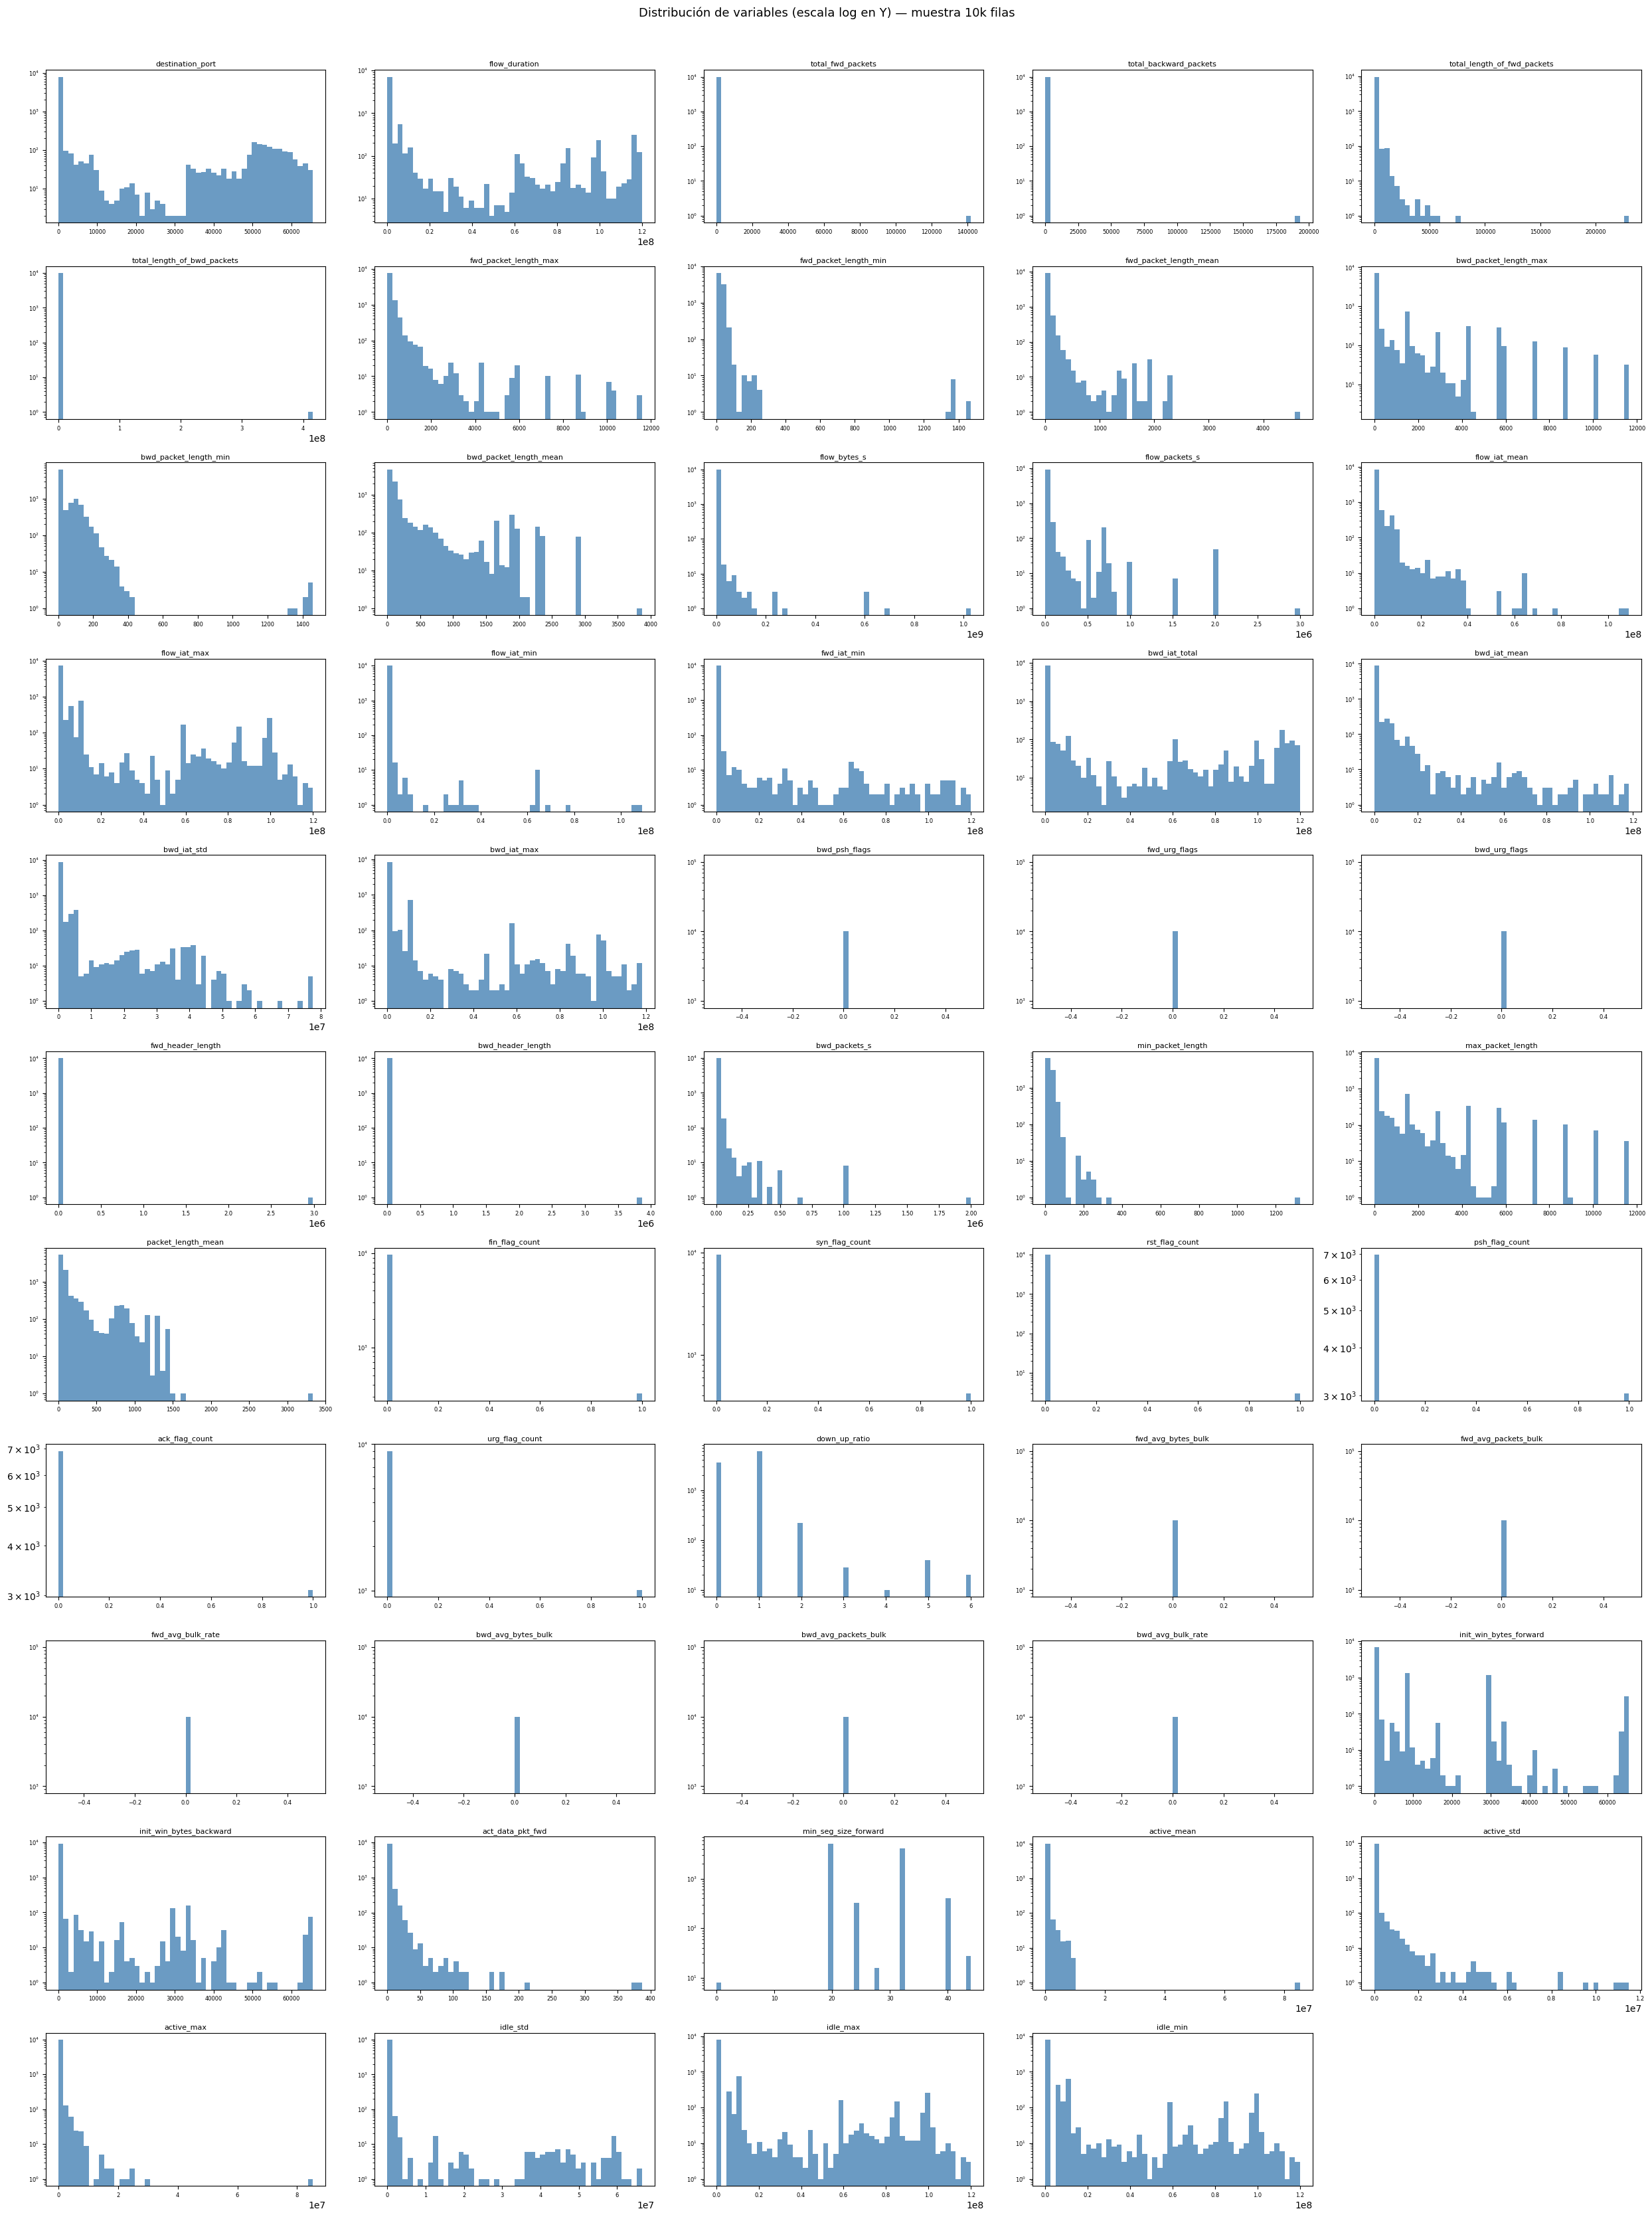

Guardado: histogramas_54cols.png


In [ ]:
# Histogramas con escalas logarítmica

# Muestreo aleatorio simple para histogramas (10k filas es suficiente)
df_sample = df_IDS[cols_numericas].sample(n=10_000, random_state=1)

n_cols = 5
n_rows = int(np.ceil(len(cols_numericas) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(25, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(cols_numericas):
    ax = axes[i]
    data = df_sample[col].dropna()

    # Escala logarítmica en Y para manejar el desbalance de frecuencias
    ax.hist(data, bins=50, color="steelblue", edgecolor="none", alpha=0.8)
    ax.set_yscale("log")
    ax.set_title(col, fontsize=8, pad=4)
    ax.tick_params(labelsize=6)
    ax.set_xlabel("")

# Ocultar ejes sobrantes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Distribución de variables (escala log en Y) — muestra 10k filas",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("histogramas_54cols.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: histogramas_54cols.png")

##### Interpretación de los histogramas (escala lineal)

Agregar las interpretaciones con el asesor.

#### Boxplot por clase

##### Muestreo estratificado

Dado el fuerte desbalance de clases presente en el dataset, un muestreo aleatorio simple podría excluir completamente a las clases minoritarias de las visualizaciones.

Para garantizar que todas las clases estén representadas en los boxplots, se empleó un **muestreo estratificado**: se seleccionaron hasta **200 filas por clase**, o el total disponible en caso de que la clase tuviera menos de ese umbral. Esto asegura que clases como `Heartbleed` (11 filas) o `Web Attack - Sql Injection` (21 filas) sean visibles en las visualizaciones, permitiendo una comparación visual equitativa entre todas las clases.

In [ ]:
# Boxplot por clase, muestreo estratificado.
# Muestreo estratificado: mínimo 200 filas por clase o el total si hay menos
N_POR_CLASE = 200

df_strat = (
    df_IDS[cols_numericas + ["label"]]
    .groupby("label", group_keys=False)
    .apply(lambda g: g.sample(n=min(len(g), N_POR_CLASE), random_state=1))
)

print(f"Tamaño muestra estratificada: {df_strat.shape}")
print(df_strat["label"].value_counts())

Tamaño muestra estratificada: (2468, 55)
label
BENIGN                        200
Bot                           200
DDoS                          200
DoS GoldenEye                 200
DoS Hulk                      200
DoS Slowhttptest              200
DoS slowloris                 200
FTP-Patator                   200
PortScan                      200
Web Attack - Brute Force      200
SSH-Patator                   200
Web Attack - XSS              200
Infiltration                   36
Web Attack - Sql Injection     21
Heartbleed                     11
Name: count, dtype: int64


/tmp/ipykernel_27414/1147725455.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(n=min(len(g), N_POR_CLASE), random_state=1))


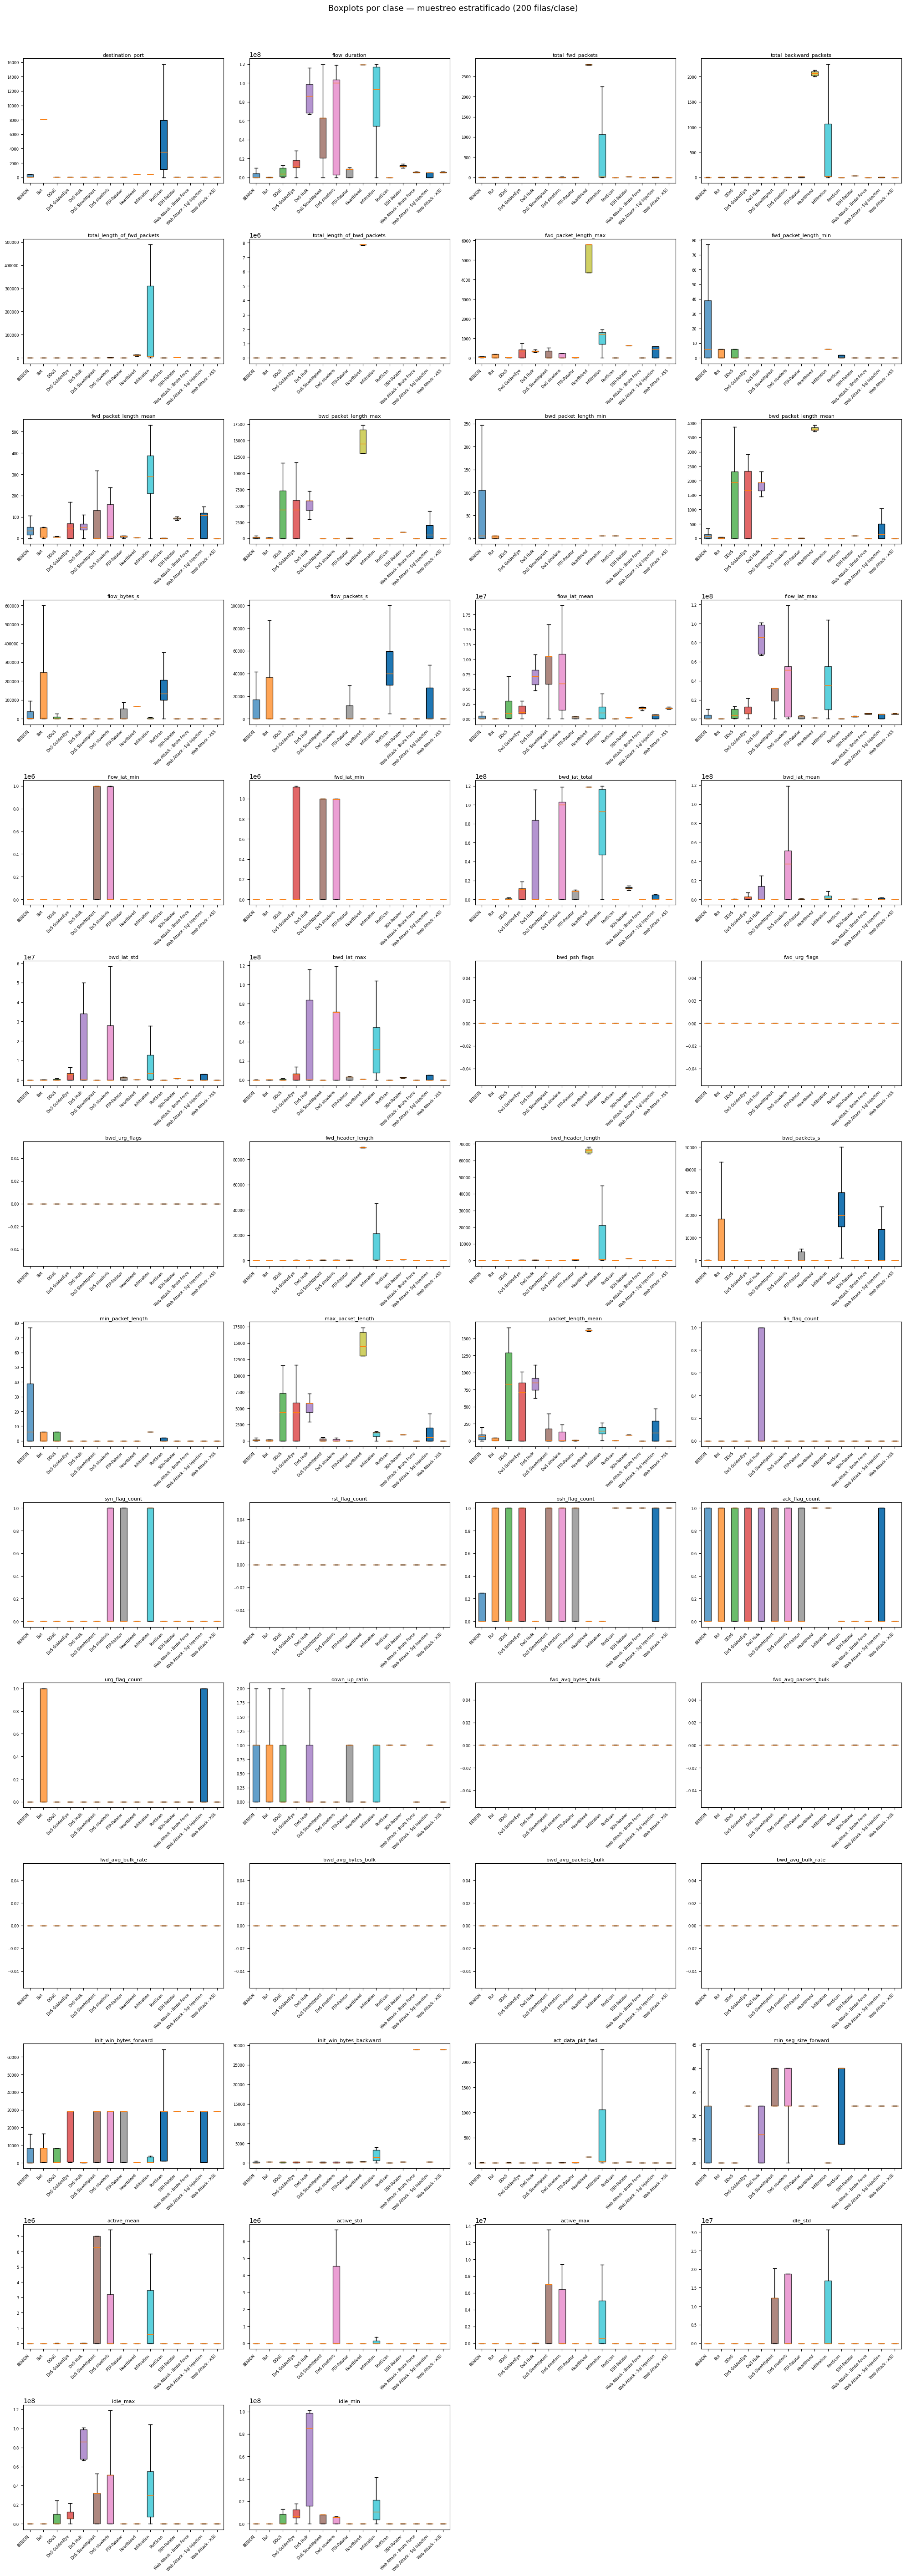

Guardado: boxplots_54cols.png


In [ ]:
# Graficamos un boxplot por columna, todas las clases en el mismo eje
clases    = sorted(df_strat["label"].unique())
n_clases  = len(clases)
colores   = plt.cm.tab10.colors[:n_clases]

n_cols = 4
n_rows = int(np.ceil(len(cols_numericas) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(cols_numericas):
    ax = axes[i]
    data_por_clase = [df_strat.loc[df_strat["label"] == c, col].dropna().values
                      for c in clases]

    bp = ax.boxplot(data_por_clase, patch_artist=True, showfliers=False)

    for patch, color in zip(bp["boxes"], colores):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    ax.set_xticks(range(1, n_clases + 1))
    ax.set_xticklabels(clases, rotation=45, ha="right", fontsize=6)
    ax.set_title(col, fontsize=8, pad=4)
    ax.tick_params(axis="y", labelsize=6)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Boxplots por clase — muestreo estratificado (200 filas/clase)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("boxplots_54cols.png", dpi=150, bbox_inches="tight")
plt.show()
print("Guardado: boxplots_54cols.png")

##### Conclusión del bloque de los bloxplots

Conclusionesssss

In [ ]:
cols_const = ['bwd_psh_flags', 'bwd_urg_flags', 'fwd_urg_flags',
              'fwd_avg_bytes_bulk', 'fwd_avg_packets_bulk', 'fwd_avg_bulk_rate',
              'bwd_avg_bytes_bulk', 'bwd_avg_packets_bulk', 'bwd_avg_bulk_rate', 'rst_flag_count']

# Si nunique == 1, es constante y se elimina
print(df_IDS[cols_const].nunique())

# rst: en qué clases aparece
print(df_IDS.groupby("label")["rst_flag_count"].sum())

bwd_psh_flags           1
bwd_urg_flags           1
fwd_urg_flags           2
fwd_avg_bytes_bulk      1
fwd_avg_packets_bulk    1
fwd_avg_bulk_rate       1
bwd_avg_bytes_bulk      1
bwd_avg_packets_bulk    1
bwd_avg_bulk_rate       1
rst_flag_count          2
dtype: int64
label
BENIGN                        686
Bot                             0
DDoS                            0
DoS GoldenEye                   0
DoS Hulk                        0
DoS Slowhttptest                0
DoS slowloris                   0
FTP-Patator                     0
Heartbleed                      0
Infiltration                    0
PortScan                        0
SSH-Patator                     0
Web Attack - Brute Force        0
Web Attack - Sql Injection      0
Web Attack - XSS                0
Name: rst_flag_count, dtype: int64


In [ ]:
print("fwd_urg_flags:")
print(df_IDS['fwd_urg_flags'].value_counts(normalize=True))

fwd_urg_flags:
fwd_urg_flags
0    0.999968
1    0.000032
Name: proportion, dtype: float64


In [ ]:
print(df_IDS.loc[df_IDS["fwd_urg_flags"] == 1, "label"].value_counts())

label
BENIGN    80
Name: count, dtype: int64


In [ ]:
# 8 columnas constantes (nunique = 1) + 2 cuasi-constantes que solo aparecen en BENIGN
cols_eliminar = [
    'bwd_psh_flags', 'bwd_urg_flags',
    'fwd_avg_bytes_bulk', 'fwd_avg_packets_bulk', 'fwd_avg_bulk_rate',
    'bwd_avg_bytes_bulk', 'bwd_avg_packets_bulk', 'bwd_avg_bulk_rate',
    'fwd_urg_flags', 'rst_flag_count',
]

df_IDS.drop(columns=cols_eliminar, inplace=True)
print(f"Nueva forma del dataset: {df_IDS.shape}")

Nueva forma del dataset: (2522220, 45)


#### Correlación de las features con la etiqueta (por clase)

Previamente se implementó una matriz de correlación para detectar redundancia entre
los features. Sin embargo, ahora se analizará **qué tan relacionado está cada feature
con la variable objetivo** (`label`).

Tomando en cuenta que la variable `label` es una variable categórica y no numérica,
se realizó una **correlación por cada clase de ataque** específico.

Se crearon columnas binarias por cada tipo de ataque, para que se indique
específicamente qué features pueden ayudarnos a detectar un tipo de ataque específico.

**Limitaciones**: La correlación de Pearson mide relaciones lineales, por lo que si
un feature presenta una correlación baja en los resultados siguientes, no
necesariamente significa que será irrelevante para el modelo final. Para un análisis
más certero, descartamos las clases con pocas muestras (`Heartbleed`, `Infiltration`,
`Web Attack - Sql Injection`).


In [ ]:
cols_numericas = [c for c in df_IDS.columns if c != "label"]
clases = sorted(df_IDS["label"].unique())

# Construir matriz: filas = features, columnas = clases
corr_matrix = pd.DataFrame(index=cols_numericas, columns=clases, dtype=float)

for clase in clases:
    binario = (df_IDS["label"] == clase).astype(int)
    for col in cols_numericas:
        corr_matrix.loc[col, clase] = df_IDS[col].corr(binario)

print(corr_matrix)
corr_matrix.to_csv('matrizCorrelacion.csv', index=False, encoding='utf-8')

                               BENIGN       Bot      DDoS  DoS GoldenEye  \
destination_port             0.159747  0.013380 -0.104810      -0.029009   
flow_duration               -0.279002 -0.012825  0.002464       0.011880   
total_fwd_packets            0.003053 -0.000248 -0.001690      -0.000352   
total_backward_packets       0.003174 -0.000216 -0.001819      -0.000475   
total_length_of_fwd_packets  0.015068  0.005395 -0.012662      -0.001166   
total_length_of_bwd_packets  0.002126 -0.000210 -0.001038      -0.000309   
fwd_packet_length_max        0.048978  0.006507 -0.066114       0.007000   
fwd_packet_length_min        0.131046 -0.007772 -0.064697      -0.020204   
fwd_packet_length_mean       0.074332  0.007193 -0.066318      -0.001305   
bwd_packet_length_max       -0.596376 -0.012597  0.411919       0.101546   
bwd_packet_length_min        0.264950 -0.015480 -0.138881      -0.038764   
bwd_packet_length_mean      -0.594315 -0.014128  0.417067       0.092797   
flow_bytes_s

#### Hallazgos por clase

**BENIGN** — Las features con mayor correlación negativa son `bwd_packet_length_max`
(-0.596), `bwd_packet_length_mean` (-0.594), `max_packet_length` (-0.555) y
`packet_length_mean` (-0.521). El signo negativo indica que estas features tienden a
tomar valores más altos en tráfico de ataque que en tráfico benigno. Por el contrario,
`bwd_packet_length_min` (+0.265) y `min_packet_length` (+0.277) son más altas en
tráfico legítimo, lo cual es consistente con el comportamiento de servidores que
responden con paquetes pequeños ante conexiones normales.

**DoS Hulk** — Es la clase con las correlaciones individuales más altas de todo el
análisis. `idle_min` (+0.721), `idle_max` (+0.699) y `flow_iat_max` (+0.692) son las
más correlacionadas. Esto es técnicamente consistente: Hulk genera ráfagas de
solicitudes HTTP intensas con períodos de inactividad entre ellas, lo que infla
directamente las métricas de tiempo de reposo (`idle`) e inter-arrival time máximo.
Le siguen las features de longitud de paquetes backward (`bwd_packet_length_mean`
+0.589, `bwd_packet_length_max` +0.582), confirmando que el servidor responde con
paquetes de gran tamaño ante cada solicitud del atacante.

**DDoS** — Correlaciones moderadas concentradas en features de longitud de paquetes:
`bwd_packet_length_mean` (+0.417), `packet_length_mean` (+0.397), `max_packet_length`
(+0.386). A diferencia de DoS Hulk, DDoS no se distingue tanto por tiempos de
inactividad sino por el volumen sostenido de tráfico, lo que explica que `idle_*` no
aparezca entre sus features más correlacionadas.

**DoS GoldenEye** — Correlaciones generalmente bajas (< 0.24 en todas las features),
siendo `flow_iat_min` (+0.236) la más destacada. El comportamiento intermitente de
GoldenEye, que mantiene conexiones HTTP abiertas de forma selectiva, no produce
patrones lineales fuertes con ningún feature individual. Su detección dependerá
de combinaciones de features en el modelo.

**DoS Slowloris y DoS Slowhttptest** — Estos ataques lentos se distinguen
principalmente por features de tiempo activo y de IAT backward. `active_mean`
(+0.267) y `active_max` (+0.172) son las más correlacionadas con Slowhttptest,
mientras que `bwd_iat_mean` (+0.177) y `fwd_iat_min` (+0.112) destacan en Slowloris.
Esto es coherente con su naturaleza: ambos ataques mantienen conexiones deliberadamente
abiertas para agotar los recursos del servidor, lo que se traduce en períodos de
actividad prolongados y tiempos de respuesta backward elevados.

**PortScan** — Su feature más correlacionada es `psh_flag_count` (+0.297), seguida
de `min_seg_size_forward` (+0.180) y `bwd_packets_s` (+0.149). A diferencia de los
ataques de volumen, PortScan se distingue más por el comportamiento de flags TCP y
ratios de tráfico que por longitudes de paquete, lo cual es consistente con el proceso
de escaneo de puertos que envía paquetes pequeños y espera respuestas mínimas.

**FTP-Patator y SSH-Patator** — Ambas clases presentan correlaciones bajas en todas
las features (< 0.07). Los ataques de fuerza bruta imitan la estructura del tráfico
legítimo de los protocolos que atacan, por lo que ningún feature individual logra
capturar una separación lineal significativa. El modelo requerirá la combinación de
múltiples features débiles para distinguirlos del tráfico benigno.

**Web Attack - Brute Force y Web Attack - XSS** — Correlaciones muy bajas en todas
las features (< 0.06). Al tratarse de ataques que viajan sobre tráfico HTTP legítimo,
sus características de red son prácticamente indistinguibles del tráfico benigno a
nivel de correlación lineal. Su detección efectiva recaerá sobre la capacidad
no-lineal del modelo.


In [ ]:
excluir = ["Heartbleed", "Infiltration"]

mapeo_familias = {
    "BENIGN":                     "Benigno",
    "DoS Hulk":                   "DoS",
    "DoS GoldenEye":              "DoS",
    "DoS slowloris":              "DoS",
    "DoS Slowhttptest":           "DoS",
    "DDoS":                       "DDoS",
    "PortScan":                   "PortScan",
    "FTP-Patator":                "Brute Force",
    "SSH-Patator":                "Brute Force",
    "Web Attack - Brute Force":   "Web Attack",
    "Web Attack - XSS":           "Web Attack",
    "Web Attack - Sql Injection": "Web Attack",
    "Bot":                        "Bot",
}

df_heat = df_IDS[~df_IDS["label"].isin(excluir)].copy()
df_heat["familia"] = df_heat["label"].map(mapeo_familias)

assert df_heat["familia"].notna().all(), "Hay clases sin mapear"
print(df_heat["familia"].value_counts())

familia
Benigno        2096342
DoS             193748
DDoS            128016
PortScan         90819
Brute Force       9152
Web Attack        2143
Bot               1953
Name: count, dtype: int64


In [ ]:
# Correlación one-vs-rest por familia
features = [c for c in df_IDS.columns if c != "label"]
orden = ["Benigno", "DoS", "DDoS", "PortScan", "Brute Force", "Web Attack", "Bot"]

corr_fam = pd.DataFrame(index=features, columns=orden, dtype=float)
for fam in orden:
    binario = (df_heat["familia"] == fam).astype(int)
    corr_fam[fam] = df_heat[features].corrwith(binario)

corr_fam.to_csv("correlacion_familias.csv")

del df_heat

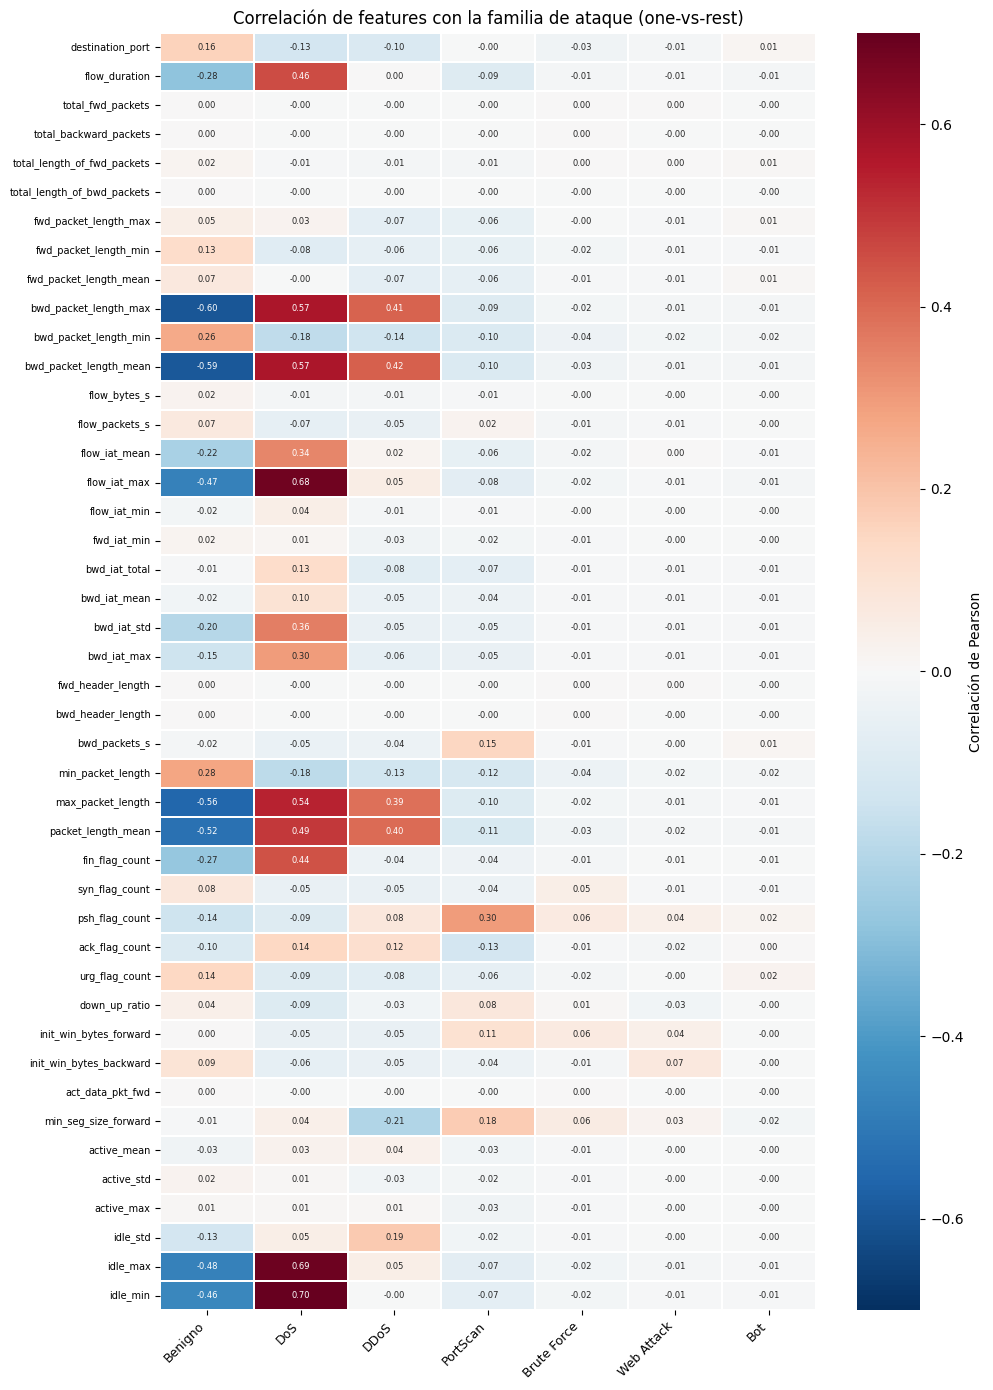

In [ ]:
# Heatmap con valores anotados
plt.figure(figsize=(10, 14))
sns.heatmap(
    corr_fam,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 6},
    cmap="RdBu_r",
    center=0,
    vmin=-0.7,
    vmax=0.7,
    linewidths=0.3,
    cbar_kws={"label": "Correlación de Pearson"}
)
plt.title("Correlación de features con la familia de ataque (one-vs-rest)", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig("correlacion_por_familia.png", dpi=150, bbox_inches="tight")
plt.show()

#### Conclusiones del análisis de correlación

**Features universalmente discriminativas** — `bwd_packet_length_mean`,
`bwd_packet_length_max`, `max_packet_length`, `packet_length_mean`, `idle_max`,
`idle_min` y `flow_iat_max` presentan las correlaciones más altas en múltiples
clases simultáneamente. Se espera que el modelo les asigne alta importancia global.

**Clases linealmente separables** — DoS Hulk y BENIGN son las clases con mayor
señal lineal en el dataset. Sus patrones son suficientemente distintos como para
que incluso modelos simples los detecten con buena precisión.

**Clases no-linealmente separables** — FTP-Patator, SSH-Patator, Web Attack - Brute
Force, Web Attack - XSS, DoS GoldenEye y PortScan presentan correlaciones bajas en
todos los features. Esto no implica que sean indetectables, sino que sus patrones
son inherentemente no-lineales. Esta observación refuerza la elección de algoritmos
basados en árboles de decisión (Random Forest, XGBoost) sobre modelos lineales como
regresión logística.

**`cwe_flag_count` confirmada como no discriminativa** — Sus correlaciones son
inferiores a 0.003 en todas las clases, confirmando desde dos análisis independientes
(correlación con label y distribución de flags por clase) que esta columna no aporta información
útil al modelo.

**`flow_bytes_s` con comportamiento inesperado** — Pese a mostrar separación visual
en los boxplots, su correlación de Pearson con todas las clases es inferior a 0.07.
Esto se atribuye a los valores negativos residuales documentados durante la limpieza,
que distorsionan el cálculo al romper la monotonía de la distribución. Se conserva
en el dataset pero se espera que el modelo la depure vía importancia de features.

**Confirmación de la limitación de Pearson** — El análisis refuerza que la correlación
lineal es insuficiente como criterio único de selección de features en este dataset.
La evaluación definitiva de relevancia se realizará mediante el `feature_importances_`
del modelo entrenado.

#### Análisis específico del contexto de red

A continuación se examinan dos dimensiones específicas del tráfico de red que no
fueron cubiertas en los apartados anteriores.

1. **Puerto de destino:** continuando con el hallazgo que se insinuaba en el boxplot
   de `destination_port`, se enfoca en identificar en qué puertos específicos se
   concentra cada tipo de tráfico.
2. **Distribución de flags TCP por clase:** identificación de si ciertos tipos de
   ataque presentan patrones distintivos en el uso de flags TCP.

**Nota:** El archivo `MachineLearningCSV` del Canadian Institute for Cybersecurity
no incluye las columnas `protocol` ni `timestamp`, al ser generado por CICFlowMeter
a partir de los archivos PCAP originales. El análisis de protocolo de red y
distribución temporal queda fuera del alcance de este dataset en su formato ML.

In [ ]:
# Puertos más frecuentes en el dataset completo
print(df_IDS['destination_port'].value_counts().head(15))

destination_port
53      876881
80      542310
443     470452
123      21313
22       10336
21        9621
389       5919
88        5150
137       2938
465       2870
8080      2689
139       2483
3268      2443
445       2090
0         1567
Name: count, dtype: int64


In [ ]:
print(df_IDS[df_IDS['destination_port'] == 0]['label'].value_counts())

label
BENIGN      1561
PortScan       6
Name: count, dtype: int64


**Hallazgo:** El puerto de destino 0 aparece en 1,561 filas de `BENIGN` y 6 filas de
`PortScan`.

**Interpretación:** Estas dos ocurrencias no comparten el mismo origen. En `BENIGN`,
el patrón es consistente con los artefactos de instrumentación de CICFlowMeter ya
documentados a lo largo de este análisis, y probablemente corresponde a un registro erróneo, no a tráfico real.

En `PortScan`, en cambio, el puerto 0 es consistente con el comportamiento **real** del
ataque: un escaneo de puertos puede recorrer todo el rango de puertos
posibles (incluyendo el puerto 0, técnicamente reservado y sin servicio asignado)
como parte de su exploración.

Este es, por tanto, un caso donde la anomalía detectada
no corresponde a un error del dataset, sino a una señal genuina del ataque.

##### Cruzar puertos con clases de ataque

Este punto se enfoca en analizar en qué puertos especificos se concentra cada clase especifica.

Es similar a lo que se hizo en los boxplot, pero con numeros concretos.

In [ ]:
for clase in clases:
    print(f"\n--- {clase} ---")
    print(df_IDS[df_IDS['label'] == clase]['destination_port'].value_counts().head(5))


--- BENIGN ---
destination_port
53     876780
443    470306
80     218033
123     21312
22       6874
Name: count, dtype: int64

--- Bot ---
destination_port
8080     1248
53730       1
4089        1
52901       1
52907       1
Name: count, dtype: int64

--- DDoS ---
destination_port
80       128013
64869         1
64873         1
27636         1
Name: count, dtype: int64

--- DoS GoldenEye ---
destination_port
80    10286
Name: count, dtype: int64

--- DoS Hulk ---
destination_port
80    172849
Name: count, dtype: int64

--- DoS Slowhttptest ---
destination_port
80    5228
Name: count, dtype: int64

--- DoS slowloris ---
destination_port
80    5385
Name: count, dtype: int64

--- FTP-Patator ---
destination_port
21    5932
80       1
Name: count, dtype: int64

--- Heartbleed ---
destination_port
444    11
Name: count, dtype: int64

--- Infiltration ---
destination_port
444    36
Name: count, dtype: int64

--- PortScan ---
destination_port
80     372
21     243
22     243
139    196
44

##### Concentración por puerto según tipo de ataque

**Hallazgo:** Al analizar `destination_port` sobre el dataset completo para cada
clase, se confirma la hipótesis de concentración dependiente del tipo de ataque.

Las clases `DoS Hulk`, `DDoS`, `DoS GoldenEye`, `DoS slowloris`, `DoS Slowhttptest`,
`Web Attack Brute Force` y `Web Attack XSS` se dirigen de forma prácticamente
exclusiva al puerto **80** (HTTP), sin variación relevante entre sus propias filas.

`DDoS` es un buen ejemplo de esto: de sus 128,016 filas, 128,013 corresponden al
puerto 80, y solo 3 filas se distribuyen en puertos distintos, cada uno apareciendo
una única vez.

`FTP-Patator` y `SSH-Patator`, por su parte, se concentran casi en su totalidad en
los puertos **21** y **22** respectivamente (los puertos de los servicios que ambos
ataques intentan vulnerar mediante fuerza bruta). En `FTP-Patator`, 5,932 de sus filas corresponden al puerto 21. En `SSH-Patator`, la totalidad de sus 3,219 filas
corresponden al puerto 22.

`PortScan`, en cambio, no presenta una concentración dominante en un solo puerto, sino que sus
conexiones se reparten entre varios puertos (80, 21, 22, 139, 445), sin que ninguno
supere una fracción reducida del total de la clase.

**Interpretación:** Este patrón es completamente coherente con la naturaleza de cada
ataque. Los ataques de tipo DoS y Web Attack tienen como objetivo agotar los recursos
o explotar vulnerabilidades de un servicio web específico, por lo que es esperable
que se dirijan consistentemente al puerto donde ese servicio opera (80). Los ataques
de fuerza bruta (`FTP-Patator`, `SSH-Patator`) están diseñados para vulnerar un
servicio puntual mediante intentos repetidos de acceso, por lo que su tráfico se
concentra necesariamente en el puerto de ese servicio. `PortScan`, en contraste,
tiene como objetivo *descubrir* qué servicios están disponibles en un sistema, por lo
que su comportamiento esperado es precisamente recorrer múltiples puertos, incluyendo
aquellos asociados a otros servicios que no cuentan con su propia clase de ataque en
este dataset (como `139` y `445`, correspondientes a NetBIOS y SMB).

**Conclusión:** Esta confirmación respalda lo que ya se había
observado visualmente en el bloque de boxplots: `destination_port` posee un fuerte
valor discriminativo, particularmente útil para distinguir ataques dirigidos a un
servicio específico (DoS, Web Attack, Fuerza Bruta) de aquellos orientados a la
exploración de múltiples servicios (`PortScan`).

##### Contraste entre boxplot y análisis sobre el dataset completo

El boxplot de `destination_port` por clase revela dos comportamientos visuales
destacables: la clase `Bot` aparece con una caja extremadamente amplia que abarca
desde valores cercanos a 0 hasta aproximadamente 50,000-55,000, y `PortScan` muestra
una caja compacta en el rango de 3,000-8,000 con bigote extendido hasta ~19,000.
El resto de las clases aparecen comprimidas cerca de cero, sin variación visual
apreciable.

Sin embargo, al contrastar estos resultados visuales con el análisis sobre el dataset
completo, se encuentran diferencias importantes:

**Clase `Bot`:** El boxplot sugiere una distribución amplia de puertos en rangos altos
(0-55,000). No obstante, el análisis completo revela que el puerto predominante es
**8080** con 1,248 ocurrencias, mientras que el resto de valores (53,730 / 4,089 /
52,901 / 52,907) aparecen una única vez. La amplitud visual de la caja se debe al
muestreo estratificado de 200 filas — con una clase de 1,966 instancias totales, la
muestra capturó una proporción mayor de los puertos dispersos en rangos altos,
diluyendo visualmente el predominio real del puerto 8080.

**Clase `PortScan`:** El boxplot muestra variación real en el rango de puertos, lo
cual es consistente con la naturaleza del ataque — un escáner de puertos por definición
contacta múltiples puertos distintos. El análisis completo confirma esta dispersión:
los puertos más frecuentes son 80 (372), 21 (243), 22 (243), 139 (196) y 445 (179),
todos ellos puertos de servicios estándar comúnmente sondeados durante un escaneo.

**Resto de clases:** La compresión visual cerca de cero no es ambigua — el análisis
completo confirma que cada clase ataca un puerto único y específico: puerto 80 para
todos los ataques DoS y Web Attacks, puerto 21 para FTP-Patator y puerto 22 para
SSH-Patator. La concentración es absoluta en la mayoría de los casos (DoS Hulk:
172,849 de sus instancias en puerto 80; DDoS: 128,013 de 128,027 en puerto 80).

**Conclusión:** Este análisis confirma dos cosas. Primero, que `destination_port`
es una feature altamente discriminativa para clases como FTP-Patator (puerto 21),
SSH-Patator (puerto 22) y los ataques DoS/Web (puerto 80), ya que presentan
concentración absoluta en puertos específicos. Segundo, que el muestreo estratificado
puede distorsionar la representación visual de clases con distribuciones muy
dispersas como `Bot`, reforzando la necesidad de contrastar siempre las
visualizaciones con el análisis sobre el dataset completo.

##### Distribución de flags TCP por clase

Los flags TCP son bits de control dentro del encabezado de cada segmento TCP que indican el estado o propósito de la conexión. En el contexto de detección de intrusiones, su distribución por clase de ataque puede revelar patrones de comportamiento específicos que no son visibles en las métricas de volumen o tiempo.

Se calculó la **proporción promedio** de cada flag por clase (es decir, qué fracción de los flujos de cada clase tiene activo cada flag) con la finalidad de identificar si ciertos ataques presentan firmas distintivas en el uso de estos bits de control.

In [ ]:
# Distribución de flags TCP por clase
flags = ['fin_flag_count', 'syn_flag_count', 'psh_flag_count',
         'ack_flag_count', 'urg_flag_count']

flags_por_clase = (
    df_IDS.groupby("label")[flags]
    .mean()
    .round(4)
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
print(flags_por_clase)
flags_por_clase.to_csv("flags_por_clase.csv")
print("\nGuardado: flags_por_clase.csv")

                            fin_flag_count  syn_flag_count  psh_flag_count  \
label                                                                        
BENIGN                              0.0106          0.0567          0.2677   
Bot                                 0.0000          0.0000          0.6288   
DDoS                                0.0002          0.0000          0.4545   
DoS GoldenEye                       0.0000          0.0000          0.7161   
DoS Hulk                            0.3408          0.0000          0.0844   
DoS Slowhttptest                    0.0000          0.1314          0.8064   
DoS slowloris                       0.0000          0.2654          0.7187   
FTP-Patator                         0.0000          0.3277          0.6698   
Heartbleed                          0.0000          0.0000          0.0909   
Infiltration                        0.0000          0.5556          0.1667   
PortScan                            0.0000          0.0000      

##### Hallazgos por clase

**`PortScan`**: Presenta la firma más clara de todo el análisis. `psh_flag_count` en 0.9993 y `ack_flag_count` prácticamente en cero (0.0007). Este patrón es técnicamente consistente con el comportamiento de un escaneo de puertos TCP que envía segmentos con PSH sin esperar confirmación de conexión establecida.

**`DoS Hulk`**: Es la única clase con `fin_flag_count` relevante (0.3408), lo cual indica que una proporción considerable de sus flujos incluyen cierres de conexión explícitos. Esto es coherente con su mecanismo: Hulk genera solicitudes HTTP completas que el servidor intenta responder antes de que la conexión sea terminada.

**`DoS slowloris` y `DoS Slowhttptest`**: Ambos presentan `syn_flag_count`
moderado (0.2654 y 0.1314 respectivamente), reflejo de que estos ataques abren múltiples conexiones TCP deliberadamente sin completarlas. `psh_flag_count` también es alto (0.72 y 0.81), consistente con el envío parcial de cabeceras HTTP para mantener las conexiones abiertas.

**`FTP-Patator` y `SSH-Patator`**: Ambos muestran `syn_flag_count` relevante
(0.3277 y 0.0043 respectivamente) y `psh_flag_count` alto (0.67 y 0.93). El SYN elevado en FTP-Patator refleja el establecimiento repetido de nuevas conexiones en cada intento de fuerza bruta. La diferencia entre ambos se explica por la naturaleza del protocolo: FTP requiere nuevas conexiones por intento, mientras que SSH puede reutilizar la misma sesión TCP para múltiples intentos.

**`Bot`**: Destaca por tener el `urg_flag_count` más alto de todas las clases (0.362), muy por encima del resto. El flag URG es extremadamente raro en tráfico legítimo y su presencia elevada es un indicador clásico de comunicación encubierta o tráfico de comando y control (C2), consistente con el comportamiento del malware tipo botnet.

**`BENIGN`**: Es la única clase con distribución balanceada entre múltiples flags (FIN: 0.011, SYN: 0.057, PSH: 0.268, ACK: 0.291, URG: 0.121), lo cual refleja la naturaleza variada del tráfico legítimo que incluye distintos tipos de conexiones y protocolos.

**`DDoS`**: Prácticamente sin `syn_flag_count` (0.0002), con dominancia de
`ack_flag_count` (0.5468) y `psh_flag_count` (0.4545). Esto sugiere que el ataque DDoS capturado en este dataset opera principalmente sobre conexiones TCP ya establecidas, inundando con segmentos de datos en lugar de nuevas solicitudes de conexión.

##### Conclusión

El análisis de flags TCP confirma que cada familia de ataque presenta una firma distinta en el uso de bits de control TCP. `PortScan` y `Bot` son las clases con los patrones más únicos y fácilmente distinguibles. Los ataques DoS lentos (Slowloris, Slowhttptest) comparten una firma similar entre sí, lo que anticipa que el modelo podría tener mayor dificultad para distinguirlos entre ellos que para separarlos del tráfico benigno.

`cwe_flag_count` queda definitivamente descartada como feature relevante tras este tercer análisis confirmatorio.

### Calidad y Confiabilidad del Dataset


#### Limitaciones conocidas:

A lo largo de la realización de este Análisis Exploratorio de Datos se identificaron múltiples problemas de calidad en el dataset. La mayoría de estos fueron atribuibles a la herramienta de extracción de características CICFlowMeter, y no al comportamiento real del tráfico de red capturado.

A continuación se presenta un resumen de los hallazgos:

- **Filas duplicadas (9.18% del dataset)**: CICFlowMeter divide incorrectamente conexiones TCP, generando registros duplicados. El impacto fue principalmente severo en la clase `PortScan` y `SSH-Patator` debido a que representaba el 42.86% y 45.41% de sus muestras respectivamente. Este problema fue documentado a su vez en otro paper (Lanvin et al., 2022).

- **Valores infinitos en `flow_bytes_s` y `flow_packets_s`**: Esto se dio debido a una división entre cero cuando `flow_duration = 0`. Se confirmó que el 100% de los casos coincidían con la condición, y que su distribución por clase no representaba un riesgo relevante de sesgo (máximo 0.51% en la clase más afectada).

- **Valores negativos físicamente imposibles en `min_seg_size_forward`, `bwd_header_length` y `fwd_header_length`:** Resultaron consistentes a un error de desbordamiento (overflow) de tipo de dato en la herramienta de extracción. Afectaron a un volumen mínimo de filas (35), todas pertenecientes a tráfico BENIGN.

- **Valores negativos en `flow_duration` (y cómo afectó indirectamente a `flow_bytes_s` y
`flow_packets_s`):** Un rango pequeño de valores negativos (mayormente -1) existían en la columna `flow_duration`, y se propagaron a otras dos columnas. Estos valores fueron atribuibles a errores de sincronización de tiempo durante la captura. Afectó a 107 filas, también exclusivas de tráfico `BENIGN`.

- **Columnas redundantes y duplicadas**: Se identificaron 24 columnas con varianza cero, cuasi-constantes sin relevancia discriminativa, o con multicolinealidad severa (correlación mayor al 0.90) frente a otras del dataset, incluyendo un caso de duplicado literal (`fwd_header_length` y `fwd_header_length.1`) el cual también fue documentado en el paper anteriormente mencionado.

- **Ausencia de columnas de protocolo y timestamp:** El archivo `MachineLearningCSV` del Canadian Institute for Cybersecurity no incluye las columnas `protocol` ni `timestamp`, al ser generado por CICFlowMeter a partir de los archivos PCAP originales. Esto limitó el bloque de Contexto de Red a únicamente el análisis de `destination_port` y distribución de flags TCP.

Un patrón consistente a lo largo del análisis es que los errores de la instrumentación empleada CICFlowMeter (infinitos, negativos, cuasi-constantes) se concentran únicamente en tráfico `BENIGN`, lo que sugiere que su tratamiento no compromete la capacidad de detección de ninguna clase de ataque, incluyendo las minoritarias.

#### Reproducibilidad

Con la finalidad de que este análisis pueda ser replicado de forma idéntica, se fijó de
manera consistente `random_state=1` en todos los procesos de muestreo aleatorio
(muestra simple y muestreo estratificado). Esto garantiza
que, al ejecutar nuevamente el código, se obtengan exactamente las mismas filas seleccionadas y, por lo tanto, las mismas visualizaciones y resultados presentados en
este documento.

## Referencias empleadas:

1.  Lanvin, M., Gimenez, P.-F., Han, Y., Majorczyk, F., & Mé, L. (2022). *Errors in the CICIDS2017 dataset and the significant differences in detection performances it makes.* 17th International Conference on Risks and Security of Internet and Systems (CRiSIS), Sousse, Tunisia, pp. 18–33. https://doi.org/10.1007/978-3-031-31108-6_2

Creacion de dataset a partir de los datos limpios.

In [ ]:
# Mapeo de clases a familias de ataque (Se eliminan Infiltration y Heartbleed como se acordó en la Metodología)
mapeo_familias = {
    "BENIGN":                        "Benigno",
    "DoS Hulk":                      "DoS",
    "DoS GoldenEye":                 "DoS",
    "DoS slowloris":                 "DoS",
    "DoS Slowhttptest":              "DoS",
    "DDoS":                          "DDoS",
    "PortScan":                      "PortScan",
    "FTP-Patator":                   "Brute Force",
    "SSH-Patator":                   "Brute Force",
    "Web Attack - Brute Force":      "Web Attack",
    "Web Attack - XSS":              "Web Attack",
    "Web Attack - Sql Injection":    "Web Attack",
    "Bot":                           "Bot"
}

df_IDS["label"] = df_IDS["label"].map(mapeo_familias)

print(df_IDS["label"].value_counts())


label
Benigno        2096342
DoS             193748
DDoS            128016
PortScan         90819
Brute Force       9152
Web Attack        2143
Bot               1953
Name: count, dtype: int64


In [ ]:
n_antes = len(df_IDS)
df_IDS = df_IDS.dropna(subset=["label"]).copy()
print(f"Filas excluidas: {n_antes - len(df_IDS)}")

Filas excluidas: 47


In [ ]:
df_IDS.to_csv("dataset_limpio.csv", index=False)
print(f"Exportado: {df_IDS.shape}")

Exportado: (2522173, 45)
